# Examen · Aprendizaje no supervisado
## Análisis de redes: de la estructura a la recomendación · Red mundial de rutas aéreas (OpenFlights)

**Integrantes:** Maximiliano Palma y Joaquin Hidalgo

---

# 0. Declaración de originalidad

## 0.1 La pregunta y la decisión que apoya

**Pregunta:** ¿qué aeropuertos son críticos para mantener conectada la red mundial de rutas aéreas y qué rutas nuevas convendría sugerir para reducir esa dependencia?

**Decisión que apoya:** dónde reforzar la conectividad y qué conexiones abrir para hacer la red menos vulnerable.

## 0.2 Tres trabajos similares y en qué se diferencia el nuestro

Reconocemos que OpenFlights es una red muy trabajada: encontramos varios proyectos que usan los mismos 3.214 aeropuertos. Por eso nuestro aporte no está en la red elegida, sino en lo que se hace con ella. La columna "Qué hace" resume lo que cada trabajo declara en su README o documento; no revisamos el código completo de cada repositorio.

| # | Trabajo | Qué hace (según su documentación) | Qué hace el nuestro que ese trabajo no hace |
|---|---|---|---|
| 1 | [Global Air Transportation Network Analysis](https://github.com/maihaan-data/air_transportation_network) (repositorio de GitHub, `maihaan-data`) | Mismos 3.214 aeropuertos. Centralidades (degree, eigenvector, closeness, betweenness), Louvain (17 comunidades, modularidad ≈ 0,65 en una ejecución), ajuste de distribuciones y modelos nulos. Afirma que las comunidades coinciden con la geografía. | Cuantificamos esa afirmación contra el atributo real (país) con NMI, ARI y pureza por país, y comparamos Greedy con Louvain. En el Hito 2 recomendamos rutas, evaluamos la recomendación, descubrimos roles estructurales y simulamos intervenciones; su documentación no incluye nada de eso. |
| 2 | [Improving Connectivity of Airline Networks](https://courses.cs.washington.edu/courses/cse547/24sp/old_projects/23wi/Airline_Network_Connectivity.pdf) (proyecto de curso, Universidad de Washington) | Louvain (38 comunidades) y recomendación de rutas nuevas entre comunidades poco conectadas, con una heurística basada en grado y distancia, evaluada contra una selección aleatoria. | En el Hito 2, nuestro recomendador usa puntajes de predicción de vínculos (vecinos comunes, Jaccard, Adamic–Adar, PageRank personalizado) y se evalúa ocultando el 20% de las aristas: HitRate@N y AUC frente a una línea base de aeropuertos populares, más cobertura y novedad. Ese trabajo no tiene evaluación con aristas ocultas ni línea base de popularidad, ni análisis de centralidades ni validación contra el país. |
| 3 | [Global Airport Network Analysis](https://github.com/Himanshi2701/Global-Airport-Network-Analysis) (repositorio de GitHub, `Himanshi2701`) | 3.214 aeropuertos, grafo dirigido. Degree, PageRank y betweenness; Louvain; resiliencia con remoción aleatoria y dirigida por degree o betweenness, medida con el tamaño de la componente gigante. | En el Hito 2 simulamos la fragmentación con más estrategias (PageRank y rol estructural, además de degree, betweenness y azar con 20 repeticiones) y más métricas (componentes, longitud característica de camino y eficiencia global). Su documentación tampoco valida las comunidades contra el país ni recomienda vínculos. |

## 0.3 El aporte

El elemento que va más allá del notebook de clase combina dos aportes de la lista del instructivo:

| Aporte | Estado | Evidencia con números |
|---|---|---|
| **Validación externa:** ¿la estructura recupera lo que sabemos del mundo? | Ejecutado en este Hito (sección 4.3) | Louvain: NMI 0,63 y ARI 0,29 contra el país (Greedy: 0,54 y 0,16). 55 de los 63 países con 10 aeropuertos o más (87%) tienen el 80% o más de sus aeropuertos en una sola comunidad. Louvain con 5 semillas: entre 24 y 27 comunidades y modularidad de 0,653 a 0,659. |
| **Recomendador consciente de comunidad:** vínculos dentro de la comunidad (cierre triádico) frente a puentes entre comunidades, y el dilema entre precisión y novedad. | Comprometido para el Hito 2 (secciones 6 y 7) | HitRate@N (N = 1, 3, 5 y 10) y AUC con el 20% de aristas ocultas, frente a la línea base de aeropuertos populares; cobertura y porcentaje de recomendaciones que cruzan comunidades. |

Ambos se conectan con la pregunta: las comunidades indican entre qué regiones faltan rutas, y los aeropuertos puente de la sección 3 (por ejemplo ANC) son los candidatos a aeropuertos críticos.

# 1. Problema y red

## 1.1 Fuente y licencia

- **Fuente:** OpenFlights, base de datos pública de aeropuertos y rutas aéreas ([datos](https://openflights.org/data.html) · [repositorio](https://github.com/jpatokal/openflights/tree/master/data)). Archivos usados: `airports.dat` y `routes.dat`.
- **Licencia:** Open Database License (ODbL).
- **Vigencia:** fotografía de las rutas aéreas hacia 2014. Las conclusiones describen la estructura de esa red, no las rutas actuales.

## 1.2 Definición de la red

| Elemento | Definición |
|---|---|
| **Nodo** | Un aeropuerto. |
| **Arista** | Existe al menos una ruta comercial directa entre dos aeropuertos, según `routes.dat`. |
| **Tipo de vínculo** | Operacional: una aerolínea declara operar una ruta regular entre ambos aeropuertos. No es comunicación, similitud ni co-ocurrencia. |
| **Dirección** | Los datos son dirigidos (origen → destino). El análisis principal usa la red no dirigida `G` (hay ruta en al menos un sentido) y conserva la versión dirigida `D`. El 95,7% de las aristas no dirigidas existen en ambos sentidos (18.048 de 18.858), por eso la pérdida de información es pequeña. |
| **Ponderación** | `n_rutas`: número de combinaciones aerolínea-ruta entre dos aeropuertos, que incluye códigos compartidos. No mide vuelos ni pasajeros. Todo el análisis se hace sobre la red sin ponderar. |
| **Atributo externo** | País del aeropuerto (campo `country` de `airports.dat`): unos 225 países y territorios en la componente gigante. No proviene de la estructura de la red. |

## 1.3 Tamaño de la red y cumplimiento de los requisitos

| Etapa de limpieza | Resultado |
|---|---|
| Filas crudas de `routes.dat` | 67.663 |
| Sin ID de origen o destino | −423 |
| Bucles (origen = destino) | −1 |
| Aeropuertos sin ficha en `airports.dat` | −469 |
| **Filas que quedan** | **66.770** (se descartó el 1,3%) |
| Pares dirigidos únicos | 36.906 |
| **Aristas no dirigidas únicas** | **18.858** |
| **Nodos** | **3.214** |
| Componente gigante | 3.188 nodos (99,2%) y 18.833 aristas (99,9%) |

| Requisito del instructivo | Mínimo | Nuestra red |
|---|---|---|
| Tamaño | ≥ 300 nodos y ≥ 1.000 aristas | 3.214 nodos y 18.858 aristas |
| Conectividad | Componente gigante ≥ 70% de los nodos | 99,2% |
| Atributo externo | Al menos uno | País |
| Definición clara | Nodo, arista, vínculo, dirección y ponderación | Ver 1.2 |
| Pregunta del proyecto | Una decisión real | Ver 0.1 |

## 1.4 Limitaciones de los datos

- **Datos de 2014:** la estructura puede haber cambiado, y no incluye aerolíneas ni rutas posteriores.
- **Sin pasajeros, frecuencias ni capacidad:** "crítico" significa estructuralmente central en la red, no necesariamente indispensable para la operación real.
- **Códigos compartidos:** cada aerolínea que declara una ruta suma al peso `n_rutas`, aunque la opere otra. Por eso el análisis no usa pesos.
- **Aeropuertos sin código IATA:** 19 aeropuertos de la red solo tienen código ICAO. En tablas y gráficos usamos una etiqueta de respaldo.

In [1]:
# Librerías principales del proyecto
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Semilla fija: hace que los resultados aleatorios (Louvain, red ER, etc.) sean reproducibles
SEED = 42
np.random.seed(SEED)

# Para ver más columnas en las tablas
pd.set_option("display.max_columns", 30)
print("networkx:", nx.__version__, "| pandas:", pd.__version__)

networkx: 3.7 | pandas: 3.0.3


In [2]:
# Fuente: OpenFlights (licencia ODbL). Se leen directo desde el repositorio oficial.
BASE = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/"

# airports.dat y routes.dat no traen encabezado, así que lo definimos nosotros.
# En estos archivos los valores faltantes vienen escritos como \N
cols_aeropuertos = ["id", "nombre", "ciudad", "pais", "iata", "icao", "lat", "lon",
                    "altitud", "zona_horaria", "dst", "tz", "tipo", "fuente"]
cols_rutas = ["aerolinea", "aerolinea_id", "origen_cod", "origen", "destino_cod", "destino",
              "codeshare", "escalas", "equipo"]

aeropuertos = pd.read_csv(BASE + "airports.dat", header=None, names=cols_aeropuertos,
                          na_values=r"\N", encoding="utf-8")
rutas = pd.read_csv(BASE + "routes.dat", header=None, names=cols_rutas,
                    na_values=r"\N", encoding="utf-8")

print("Aeropuertos crudos:", aeropuertos.shape)   # esperado: (7698, 14)
print("Rutas crudas:", rutas.shape)               # esperado: (67663, 9)
aeropuertos.head()

Aeropuertos crudos: (7698, 14)
Rutas crudas: (67663, 9)


,id,nombre,ciudad,pais,iata,icao,lat,lon,altitud,zona_horaria,dst,tz,tipo,fuente
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.081690,145.391998,5282,10.0,U,Pacific/Port_Moresby,airport,OurAirports
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.207080,145.789001,20,10.0,U,Pacific/Port_Moresby,airport,OurAirports
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.826790,144.296005,5388,10.0,U,Pacific/Port_Moresby,airport,OurAirports
3,4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977,239,10.0,U,Pacific/Port_Moresby,airport,OurAirports
4,5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.443380,147.220001,146,10.0,U,Pacific/Port_Moresby,airport,OurAirports


# 2. Construcción de la red y medidas globales

En esta sección pasamos de los datos crudos de OpenFlights a una red lista para analizar y la caracterizamos a nivel global, es decir, miramos la red completa y no a cada aeropuerto por separado.

## Qué vamos a hacer

| Paso | Qué hacemos | Para qué |
|---|---|---|
| **2.1 Limpieza** | Quitamos rutas sin identificador, bucles (rutas de un aeropuerto a sí mismo) y aeropuertos sin ficha, y revisamos que todos los nodos tengan país. | Que cada nodo y cada arista de la red sean válidos y trazables. |
| **2.2 Aristas únicas** | Colapsamos las filas repetidas de `routes.dat` (una por aerolínea) en una arista por par de aeropuertos, con peso `n_rutas`. | Evitar contar varias veces la misma conexión. |
| **2.3 Grafos** | Construimos `G` (no dirigido y ponderado) y `D` (dirigido), con país, ciudad y coordenadas como atributos de cada nodo. | `G` será la base del análisis; `D` conserva el sentido de las rutas. |
| **2.4 Matriz de adyacencia** | Representamos la red como matriz `A` y verificamos que sea simétrica y de diagonal nula. | Comprobar que la red está bien construida. |
| **2.5 Componente gigante** | Extraemos la componente conexa más grande y vemos qué porcentaje de la red conserva. | Las distancias solo se pueden medir dentro de una componente conexa. |
| **2.6 Medidas globales** | Calculamos densidad, grado medio, máximo y mínimo, diámetro, camino medio y clustering medio. | Describir la forma general de la red. |
| **2.7 Distribución de grado** | Histograma y gráfico log-log. | Ver si hay pocos aeropuertos muy conectados (cola larga) o si todos se parecen. |
| **2.8 Red aleatoria** | Comparamos con una red Erdős–Rényi con los mismos nodos y aristas. | Identificar qué tiene OpenFlights que el azar no produce. |
| **2.9 Hallazgos** | Cerramos con 3 a 5 conclusiones sobre la estructura global. | Dejar claro qué aprendimos de la red. |

## Decisiones de construcción

- **Nodo:** un aeropuerto. **Arista:** existe al menos una ruta comercial directa entre dos aeropuertos.
- **Red no dirigida:** la mayoría de las rutas existen en ambos sentidos, y las medidas globales y la modularidad se definen de forma más limpia así. La versión dirigida (`D`) se conserva para análisis posteriores.
- **Peso `n_rutas`:** cuenta combinaciones aerolínea-ruta entre dos aeropuertos, no vuelos. Es una aproximación de cuánta oferta hay en cada conexión.
- **Distancias sobre la componente gigante:** el diámetro y el camino medio solo están definidos dentro de una componente conexa.
- **Limitación de los datos:** `routes.dat` es una fotografía de las rutas aéreas hacia 2014. Las conclusiones describen la estructura de esa red, no las rutas actuales.

In [3]:
# Cada paso de limpieza reporta cuántas filas quita. Esto es lo que pide el instructivo
# (duplicados, bucles, nodos sin atributo, normalización de identificadores).

n0 = len(rutas)

# 1) Rutas sin ID de origen o destino (vienen como \N): no podemos ubicarlas en la red
rutas = rutas.dropna(subset=["origen", "destino"]).copy()
print(f"Sin ID de origen/destino: {n0 - len(rutas)} filas eliminadas")

# 2) Normalizar identificadores: pasaron a float por los NaN, los volvemos enteros
rutas["origen"] = rutas["origen"].astype(int)
rutas["destino"] = rutas["destino"].astype(int)

# 3) Bucles (self-loops): rutas de un aeropuerto a sí mismo
n1 = len(rutas)
rutas = rutas[rutas["origen"] != rutas["destino"]]
print(f"Bucles (origen = destino): {n1 - len(rutas)} filas eliminadas")

# 4) Aeropuertos que aparecen en rutas pero no existen en airports.dat
n2 = len(rutas)
ids_validos = set(aeropuertos["id"])
rutas = rutas[rutas["origen"].isin(ids_validos) & rutas["destino"].isin(ids_validos)]
print(f"Aeropuertos sin ficha en airports.dat: {n2 - len(rutas)} filas eliminadas")

# 5) Nodos sin atributo externo (país)
ids_en_rutas = set(rutas["origen"]) | set(rutas["destino"])
sin_pais = aeropuertos[aeropuertos["id"].isin(ids_en_rutas) & aeropuertos["pais"].isna()]
print(f"Aeropuertos de la red sin país: {len(sin_pais)}")

print(f"\nRutas que quedan: {len(rutas)} de {n0}")

Sin ID de origen/destino: 423 filas eliminadas
Bucles (origen = destino): 1 filas eliminadas
Aeropuertos sin ficha en airports.dat: 469 filas eliminadas
Aeropuertos de la red sin país: 0

Rutas que quedan: 66770 de 67663


In [4]:
# Una fila de routes.dat = una aerolínea operando una ruta. Hay muchas filas para el
# mismo par de aeropuertos, así que las colapsamos: el peso = cuántas rutas hay en el par.

# Aristas dirigidas únicas (A -> B es distinto de B -> A)
aristas_dir = (rutas.groupby(["origen", "destino"]).size()
                    .reset_index(name="n_rutas"))
print("Pares dirigidos únicos:", len(aristas_dir))      # esperado: 36906

# Versión no dirigida: ordenamos cada par (u < v) y sumamos los pesos de ida y vuelta
aristas_dir["u"] = aristas_dir[["origen", "destino"]].min(axis=1)
aristas_dir["v"] = aristas_dir[["origen", "destino"]].max(axis=1)
aristas = (aristas_dir.groupby(["u", "v"], as_index=False)["n_rutas"].sum())
print("Aristas no dirigidas únicas:", len(aristas))     # esperado: 18858
aristas.head()

Pares dirigidos únicos: 36906
Aristas no dirigidas únicas: 18858


,u,v,n_rutas
0,1,2,2
1,1,3,2
2,1,4,2
3,1,5,4
4,2,3,2


In [5]:
# Información de cada aeropuerto, indexada por ID para pegársela a los nodos
info = aeropuertos.set_index("id")[["nombre", "ciudad", "pais", "iata", "lat", "lon"]]

# Grafo no dirigido y ponderado (el que usaremos para casi todo el análisis)
G = nx.Graph()
G.add_weighted_edges_from(zip(aristas["u"], aristas["v"], aristas["n_rutas"]))
nx.set_node_attributes(G, info.loc[list(G.nodes)].to_dict("index"))

# Grafo dirigido (lo guardamos para análisis de rutas de ida y vuelta más adelante)
D = nx.DiGraph()
D.add_weighted_edges_from(zip(aristas_dir["origen"], aristas_dir["destino"], aristas_dir["n_rutas"]))

print("G (no dirigido):", G.number_of_nodes(), "nodos,", G.number_of_edges(), "aristas")
print("D (dirigido):   ", D.number_of_nodes(), "nodos,", D.number_of_edges(), "aristas")

# Verificación rápida de que los atributos quedaron bien pegados
nodo_ejemplo = list(G.nodes)[0]
print(nodo_ejemplo, G.nodes[nodo_ejemplo])

G (no dirigido): 3214 nodos, 18858 aristas
D (dirigido):    3214 nodos, 36906 aristas
1 {'nombre': 'Goroka Airport', 'ciudad': 'Goroka', 'pais': 'Papua New Guinea', 'iata': 'GKA', 'lat': -6.081689834590001, 'lon': 145.391998291}


In [6]:
# Matriz de adyacencia A: A[i, j] = 1 si hay ruta directa entre el aeropuerto i y el j.
# Fijamos el orden de los nodos para que la fila i siempre sea el mismo aeropuerto.
nodos = list(G.nodes)
A = nx.to_numpy_array(G, nodelist=nodos, weight=None)   # weight=None -> matriz binaria 0/1

print("Forma de A:", A.shape)
print("¿Simétrica? (red no dirigida):", np.allclose(A, A.T))
print("¿Diagonal nula? (sin bucles):", np.trace(A) == 0)
print("Suma de A / 2 =", int(A.sum() / 2), "-> debe coincidir con el número de aristas:", G.number_of_edges())

Forma de A: (3214, 3214)
¿Simétrica? (red no dirigida): True
¿Diagonal nula? (sin bucles): True
Suma de A / 2 = 18858 -> debe coincidir con el número de aristas: 18858


In [7]:
# Las medidas de distancia (diámetro, camino medio) solo existen dentro de una componente conexa,
# así que trabajamos con la más grande: la componente gigante.
componentes = sorted(nx.connected_components(G), key=len, reverse=True)
Gc = G.subgraph(componentes[0]).copy()

print("Número de componentes:", len(componentes))
print("Tamaños de las componentes:", [len(c) for c in componentes])
print(f"Componente gigante: {Gc.number_of_nodes()} nodos "
      f"({Gc.number_of_nodes() / G.number_of_nodes():.1%} de los nodos) y "
      f"{Gc.number_of_edges()} aristas ({Gc.number_of_edges() / G.number_of_edges():.1%} de las aristas)")

Número de componentes: 7
Tamaños de las componentes: [3188, 10, 4, 4, 4, 2, 2]
Componente gigante: 3188 nodos (99.2% de los nodos) y 18833 aristas (99.9% de las aristas)


In [8]:
# Medidas globales de G (y las de distancia, sobre la componente gigante Gc)
grados = [d for _, d in G.degree()]

medidas = {
    "Nodos": G.number_of_nodes(),
    "Aristas": G.number_of_edges(),
    "Densidad": nx.density(G),
    "Grado medio": np.mean(grados),
    "Grado máximo": max(grados),
    "Grado mínimo": min(grados),
    "Número de componentes": nx.number_connected_components(G),
    "Diámetro (componente gigante)": nx.diameter(Gc),                       # puede tardar unos segundos
    "Camino medio (componente gigante)": nx.average_shortest_path_length(Gc),
    "Clustering medio": nx.average_clustering(G),
}
tabla_global = pd.DataFrame.from_dict(medidas, orient="index", columns=["OpenFlights"])
tabla_global.round(4)

,OpenFlights
Nodos,3214.0000
Aristas,18858.0000
Densidad,0.0037
Grado medio,11.7349
Grado máximo,248.0000
Grado mínimo,1.0000
Número de componentes,7.0000
Diámetro (componente gigante),12.0000
Camino medio (componente gigante),3.9585
Clustering medio,0.4918


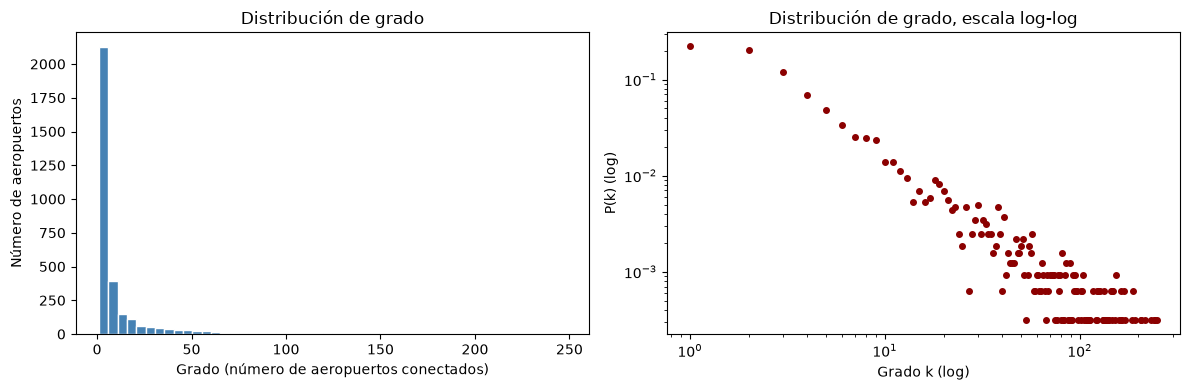

In [9]:
# ¿Cuántos aeropuertos tienen k conexiones? Histograma normal y gráfico log-log.
from collections import Counter
conteo = Counter(grados)
ks = np.array(sorted(conteo))
pk = np.array([conteo[k] for k in ks]) / len(grados)    # P(k): fracción de nodos con grado k

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma: muestra la forma general (muchos nodos de grado bajo, pocos de grado muy alto)
ejes[0].hist(grados, bins=50, color="steelblue", edgecolor="white")
ejes[0].set_xlabel("Grado (número de aeropuertos conectados)")
ejes[0].set_ylabel("Número de aeropuertos")
ejes[0].set_title("Distribución de grado")

# Log-log: si la cola se acerca a una recta, hay cola larga (pocos hubs enormes)
ejes[1].loglog(ks, pk, "o", markersize=4, color="darkred")
ejes[1].set_xlabel("Grado k (log)")
ejes[1].set_ylabel("P(k) (log)")
ejes[1].set_title("Distribución de grado, escala log-log")

plt.tight_layout()
plt.show()

In [10]:
# Red aleatoria con los mismos n y m que la nuestra: las aristas se reparten al azar.
# Sirve para ver qué tiene OpenFlights que el azar NO produce.
n, m = G.number_of_nodes(), G.number_of_edges()
ER = nx.gnm_random_graph(n, m, seed=SEED)

# Misma regla que con G: las distancias se miden en la componente gigante
comp_er = max(nx.connected_components(ER), key=len)
ER_c = ER.subgraph(comp_er).copy()
grados_er = [d for _, d in ER.degree()]

comparacion = pd.DataFrame({
    "OpenFlights": [n, m, nx.density(G), nx.diameter(Gc), nx.average_shortest_path_length(Gc),
                    nx.average_clustering(G), max(grados)],
    "Erdős–Rényi": [n, m, nx.density(ER), nx.diameter(ER_c), nx.average_shortest_path_length(ER_c),
                    nx.average_clustering(ER), max(grados_er)],
}, index=["Nodos", "Aristas", "Densidad", "Diámetro", "Camino medio", "Clustering medio", "Grado máximo"])
comparacion.round(4)

,OpenFlights,Erdős–Rényi
Nodos,3214.0000,3214.0000
Aristas,18858.0000,18858.0000
Densidad,0.0037,0.0037
Diámetro,12.0000,6.0000
Camino medio,3.9585,3.5568
Clustering medio,0.4918,0.0035
Grado máximo,248.0000,28.0000


In [11]:
# Cifras de apoyo para los hallazgos: así cada afirmación del texto tiene un número en el notebook.
g = np.array(grados)

print("Mediana del grado:", np.median(g))
print(f"Aeropuertos con una sola conexión: {(g == 1).mean():.1%}")
print(f"Aeropuertos con 5 conexiones o menos: {(g <= 5).mean():.1%}")
print(f"Aeropuertos con 50 conexiones o más: {(g >= 50).sum()} ({(g >= 50).mean():.1%})")

# ¿Cuánto concentra el 1% de aeropuertos más conectados? (suma de sus grados / suma de todos los grados)
k = round(0.01 * len(g))
concentracion = np.sort(g)[::-1][:k].sum() / g.sum()
print(f"El 1% más conectado ({k} aeropuertos) concentra el {concentracion:.1%} de la suma de grados")

print(f"Clustering real / aleatorio: {comparacion.loc['Clustering medio', 'OpenFlights'] / comparacion.loc['Clustering medio', 'Erdős–Rényi']:.0f} veces")
print(f"Grado máximo real / aleatorio: {comparacion.loc['Grado máximo', 'OpenFlights'] / comparacion.loc['Grado máximo', 'Erdős–Rényi']:.1f} veces")

Mediana del grado: 3.0
Aeropuertos con una sola conexión: 22.3%
Aeropuertos con 5 conexiones o menos: 66.2%
Aeropuertos con 50 conexiones o más: 190 (5.9%)
El 1% más conectado (32 aeropuertos) concentra el 14.8% de la suma de grados
Clustering real / aleatorio: 140 veces
Grado máximo real / aleatorio: 8.9 veces


## 2.9 Hallazgos sobre la estructura global

1. **Casi toda la red es una sola pieza.** Hay 7 componentes, pero la gigante reúne 3.188 de los 3.214 aeropuertos (99,2%) y 18.833 de las 18.858 rutas (99,9%). Las otras 6 componentes suman solo 26 aeropuertos. Todas las medidas de distancia se calculan sobre la gigante sin perder prácticamente nada de la red.

2. **Es una red muy dispersa, pero de mundo pequeño.** La densidad es 0,0037: cada aeropuerto está conectado, en promedio, con unos 12 de los 3.213 posibles (grado medio 11,7). Aun así, el camino medio es 3,96, es decir, cualquier par de aeropuertos de la gigante está en promedio a unos 4 vuelos de distancia. Es muy parecido al de la red aleatoria (3,56).

3. **Hay pocos hubs y muchísimos aeropuertos pequeños.** La mediana del grado es 3, el 22,3% de los aeropuertos tiene una sola conexión y el 66,2% tiene 5 o menos. En el otro extremo, 190 aeropuertos (5,9%) tienen 50 conexiones o más, y el máximo es 248, unas 9 veces el máximo de la red aleatoria (28). El 1% más conectado (32 aeropuertos) concentra el 14,8% de la suma de grados. El gráfico log-log baja casi en línea recta, lo que indica una cola larga que el azar no produce.

4. **La red está muy agrupada.** El clustering medio es 0,49 frente a 0,0035 en la red aleatoria, unas 140 veces mayor: si dos aeropuertos están conectados a un tercero, es muy probable que también estén conectados entre sí. Nuestra hipótesis es que esto refleja agrupaciones regionales de rutas, algo que contrastaremos con las comunidades y el atributo país en la sección 4.

5. **La periferia está más lejos de lo que el azar predice.** El diámetro es 12, el doble que el de la red aleatoria (6), aunque el camino medio sea parecido. Esto sugiere que existen aeropuertos periféricos a muchos saltos del centro, que dependen de unos pocos hubs para conectarse con el resto. Anticipa nuestra pregunta del proyecto: qué aeropuertos son críticos para mantener conectada la red.

# 3. Centralidades

La sección 2 describió la red completa. Aquí miramos a cada aeropuerto: **¿qué posición ocupa en la red y qué tipo de poder le da esa posición?** Una centralidad es un número que resume esa posición, y cada medida responde una pregunta distinta.

## Qué vamos a hacer

| Paso | Qué hacemos | Para qué |
|---|---|---|
| **3.1 Cálculo a mano** | Elegimos un subgrafo de 7 aeropuertos, calculamos degree, closeness y clustering de tres de ellos con la matriz de adyacencia y verificamos con NetworkX. | Entender de dónde sale cada número antes de dejar que el código lo calcule por toda la red. |
| **3.2 Centralidades de toda la red** | Calculamos degree, closeness, betweenness, eigenvector, PageRank y clustering para los 3.214 aeropuertos y las reunimos en la tabla `df_nodos`. | Tener una tabla única de la que salen todos los análisis siguientes. |
| **3.3 Top 10 por medida** | Listamos los 10 aeropuertos más centrales según cada medida. | Ver si las medidas coinciden o señalan aeropuertos distintos. |
| **3.4 Tres formas de poder** | Identificamos al coordinador (alto degree), al puente (alto betweenness con degree moderado) y al de status (alto eigenvector). | Traducir las medidas al lenguaje del dominio: qué aeropuerto manda y por qué. |
| **3.5 Gráficos** | Dispersión degree vs. betweenness y perfil radar de actores relevantes para la pregunta. | Ver de un vistazo quién es hub y quién es puente. |
| **3.6 Correlación entre medidas** | Matriz de correlación entre las seis medidas. | Saber cuáles medidas dicen lo mismo y cuáles aportan información distinta. |

## Cómo se interpreta cada medida en OpenFlights

| Medida | Pregunta que responde | En esta red |
|---|---|---|
| **Degree** | ¿Con cuántos aeropuertos se conecta directamente? | Aeropuerto con muchas rutas directas: el coordinador. |
| **Closeness** | ¿Qué tan cerca está, en número de vuelos, de todos los demás? | Aeropuerto desde el que se llega a todas partes con pocas escalas. |
| **Betweenness** | ¿Cuántos caminos mínimos entre otros aeropuertos pasan por él? | Aeropuerto puente: si cierra, muchos recorridos se alargan o se cortan. |
| **Eigenvector** | ¿Está conectado a aeropuertos que a su vez están muy conectados? | Aeropuerto con status: conectado al núcleo de la red. |
| **PageRank** | Similar al eigenvector, ponderando por cuántas conexiones reparte cada vecino. | Importancia "heredada" de los vecinos importantes. |
| **Clustering** | ¿Los vecinos del aeropuerto están conectados entre sí? | Alto: pertenece a un grupo cerrado. Bajo: conecta grupos separados. |

Subgrafo: 7 nodos, 10 aristas


,SCL,PMC,PUQ,IPC,EZE,GRU,LIM
SCL,0,1,1,1,1,1,1
PMC,1,0,1,0,0,0,0
PUQ,1,1,0,0,0,0,0
IPC,1,0,0,0,0,0,0
EZE,1,0,0,0,0,1,1
GRU,1,0,0,0,1,0,1
LIM,1,0,0,0,1,1,0


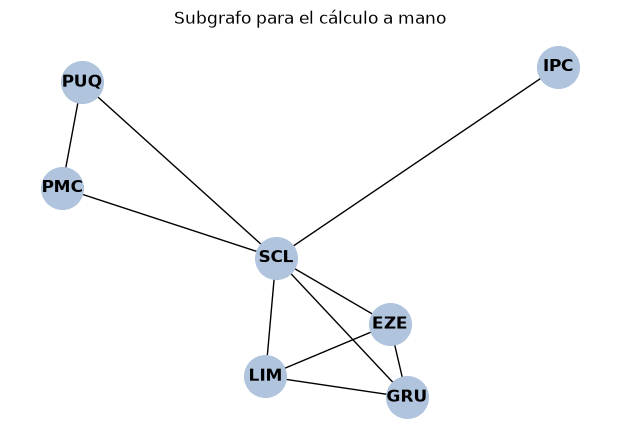

In [12]:
# Subgrafo de 7 aeropuertos para el cálculo a mano: Santiago y algunos vecinos de distinto tipo.
codigos = ["SCL", "PMC", "PUQ", "IPC", "EZE", "GRU", "LIM"]

# Buscamos el ID de cada aeropuerto a partir de su código IATA
iata_a_id = {G.nodes[n]["iata"]: n for n in G.nodes}
ids_sub = [iata_a_id[c] for c in codigos]

# Subgrafo inducido: solo las rutas que existen entre estos 7 aeropuertos.
# Renombramos los nodos con su código IATA para que todo sea legible.
S = G.subgraph(ids_sub).copy()
S = nx.relabel_nodes(S, {i: G.nodes[i]["iata"] for i in ids_sub})
print("Subgrafo:", S.number_of_nodes(), "nodos,", S.number_of_edges(), "aristas")

# Matriz de adyacencia del subgrafo, con etiquetas
A_s = nx.to_numpy_array(S, nodelist=codigos, weight=None).astype(int)
display(pd.DataFrame(A_s, index=codigos, columns=codigos))

# Dibujo del subgrafo
plt.figure(figsize=(6, 4))
pos = nx.spring_layout(S, seed=SEED)
nx.draw(S, pos, with_labels=True, node_color="lightsteelblue", node_size=900, font_weight="bold")
plt.title("Subgrafo para el cálculo a mano")
plt.show()

## 3.1 Cálculo a mano en un subgrafo de 7 aeropuertos

Trabajamos con SCL (Santiago), IPC (Isla de Pascua) y PMC (Puerto Montt). Elegimos estos tres porque representan posiciones muy distintas: un centro, una periferia y un grupo cerrado. Las fórmulas son:

- **Degree:** suma de la fila del nodo en la matriz de adyacencia, `k_i = Σ_j A_ij`.
- **Closeness (normalizada):** `C_i = (n − 1) / Σ_j d(i, j)`, con `n = 7` y `d(i, j)` la distancia mínima en vuelos.
- **Clustering:** `C_i = 2·e_i / (k_i·(k_i − 1))`, con `e_i` el número de aristas entre los vecinos de `i`.

### Degree (suma de cada fila)

| Aeropuerto | Fila | Degree |
|---|---|---|
| SCL | 0+1+1+1+1+1+1 | **6** |
| PMC | 1+0+1+0+0+0+0 | **2** |
| IPC | 1+0+0+0+0+0+0 | **1** |

### Closeness

| Aeropuerto | Distancias a los otros 6 | Σ d | Closeness |
|---|---|---|---|
| SCL | 1, 1, 1, 1, 1, 1 | 6 | 6/6 = **1,0000** |
| PMC | PUQ=1, SCL=1, IPC=2, EZE=2, GRU=2, LIM=2 | 10 | 6/10 = **0,6000** |
| IPC | SCL=1, PMC=2, PUQ=2, EZE=2, GRU=2, LIM=2 | 11 | 6/11 = **0,5455** |

### Clustering

- **SCL:** `k = 6`. Entre sus vecinos hay 4 aristas (PMC–PUQ, EZE–GRU, EZE–LIM, GRU–LIM), de 15 pares posibles. `C = 2·4 / (6·5) = 8/30 =` **0,2667**.
- **PMC:** `k = 2`, con vecinos SCL y PUQ, que están conectados entre sí. `C = 2·1 / (2·1) =` **1,0000**.
- **IPC:** `k = 1`, no existe ningún par de vecinos. Por convención `C =` **0**.

### Interpretación

- **SCL** es el centro del subgrafo: llega a todos en un vuelo (closeness 1). Su clustering es bajo porque sus vecinos forman dos grupos cerrados (PMC–PUQ y EZE–GRU–LIM) que no se conectan entre sí. SCL es lo que los une, que es la idea de puente.
- **IPC** depende por completo de SCL: tiene una sola conexión dentro del subgrafo y la closeness más baja. En la red completa tiene 2 conexiones; la otra queda fuera del subgrafo.
- **PMC** pertenece a un triángulo cerrado con SCL y PUQ: clustering máximo.
- **Ojo:** el degree dentro del subgrafo no es el degree en la red completa. Por ejemplo, GRU tiene degree 3 aquí, pero es uno de los hubs de toda la red.

In [13]:
# Verificación: NetworkX debe dar exactamente lo que calculamos a mano.
verificacion = pd.DataFrame({
    "degree (subgrafo)": dict(S.degree()),
    "closeness": nx.closeness_centrality(S),
    "clustering": nx.clustering(S),
}).loc[codigos]

# Para contrastar: el degree de cada aeropuerto en la red completa
verificacion["degree (red completa)"] = [G.degree(iata_a_id[c]) for c in codigos]

# El degree también se puede leer como la suma de las filas de la matriz
print("Degree desde la matriz coincide:", (A_s.sum(axis=1) == verificacion["degree (subgrafo)"].values).all())
verificacion.round(4)

Degree desde la matriz coincide: True


,degree (subgrafo),closeness,clustering,degree (red completa)
SCL,6,1.0000,0.2667,41
PMC,2,0.6000,1.0000,5
PUQ,2,0.6000,1.0000,5
IPC,1,0.5455,0.0000,2
EZE,3,0.6667,1.0000,41
GRU,3,0.6667,1.0000,92
LIM,3,0.6667,1.0000,56


## 3.2 Centralidades de toda la red

Calculamos las seis medidas para los 3.214 aeropuertos y las reunimos en una sola tabla, `df_nodos`, de la que salen todos los análisis posteriores.

**Decisiones de cálculo**

- **Sin pesos:** todas las medidas se calculan sobre la red sin ponderar. El peso `n_rutas` mide oferta (cuántas aerolíneas operan la ruta), no distancia ni costo, y mezclarlo con medidas de caminos mínimos distorsionaría su interpretación. Así las seis medidas son comparables entre sí.
- **Closeness en una red con 7 componentes:** NetworkX la corrige según la fracción de aeropuertos alcanzables, de modo que los aeropuertos de las componentes pequeñas no obtienen valores inflados.
- **PageRank:** factor de amortiguación 0,85 (valor estándar).
- **Betweenness:** cálculo exacto sobre todos los pares de aeropuertos, por eso es la celda más lenta (unos 30 segundos).

In [14]:
# Las seis centralidades para todos los aeropuertos. Tarda ~40 s en total (la lenta es betweenness).
# Todas sin pesos (weight=None): n_rutas mide oferta, no distancia.
grado       = dict(G.degree())
closeness   = nx.closeness_centrality(G)                              # corrige por componentes (Wasserman-Faust)
betweenness = nx.betweenness_centrality(G)                            # exacta
eigenvector = nx.eigenvector_centrality(G, max_iter=1000, tol=1e-08, weight=None)
pagerank    = nx.pagerank(G, alpha=0.85, weight=None)
clustering  = nx.clustering(G)

# Tabla única: una fila por aeropuerto, con sus atributos y sus seis medidas
df_nodos = pd.DataFrame({
    "iata":   {n: G.nodes[n]["iata"]   for n in G},
    "nombre": {n: G.nodes[n]["nombre"] for n in G},
    "ciudad": {n: G.nodes[n]["ciudad"] for n in G},
    "pais":   {n: G.nodes[n]["pais"]   for n in G},
    "degree": grado,
    "closeness": closeness,
    "betweenness": betweenness,
    "eigenvector": eigenvector,
    "pagerank": pagerank,
    "clustering": clustering,
})
df_nodos.index.name = "id"

print("Filas:", len(df_nodos), "| valores faltantes:", int(df_nodos.isna().sum().sum()))
df_nodos.head()

Filas: 3214 | valores faltantes: 19


,iata,nombre,ciudad,pais,degree,closeness,betweenness,eigenvector,pagerank,clustering
id,,,,,,,,,,
1,GKA,Goroka Airport,Goroka,Papua New Guinea,4,0.226952,0.000000e+00,0.000054,0.000224,1.000000
2,MAG,Madang Airport,Madang,Papua New Guinea,7,0.227001,7.105836e-07,0.000056,0.000375,0.571429
3,HGU,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,9,0.227033,2.034853e-06,0.000057,0.000484,0.388889
4,LAE,Nadzab Airport,Nadzab,Papua New Guinea,9,0.227033,1.970254e-06,0.000058,0.000478,0.388889
5,POM,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,32,0.294176,1.450479e-02,0.003570,0.001538,0.125000


In [15]:
# 19 aeropuertos de la red no tienen código IATA (solo ICAO). Creamos una etiqueta de respaldo
# para usarla en gráficos y tablas: el IATA cuando existe y, si no, el ICAO.
df_nodos["icao"] = aeropuertos.set_index("id")["icao"].reindex(df_nodos.index)
df_nodos["etiqueta"] = df_nodos["iata"].fillna(df_nodos["icao"])

print("Aeropuertos sin código IATA:", int(df_nodos["iata"].isna().sum()))
print("Etiquetas faltantes:", int(df_nodos["etiqueta"].isna().sum()))
df_nodos[df_nodos["iata"].isna()][["etiqueta", "nombre", "ciudad", "pais"]].head()

Aeropuertos sin código IATA: 19
Etiquetas faltantes: 0


,etiqueta,nombre,ciudad,pais
id,,,,
7275,CYJQ,Denny Island Airport,Bella Bella,Canada
2223,OPRN,Benazir Bhutto International Airport,Islamabad,Pakistan
5511,CYSG,St Georges Airport,Lutselk'e,Canada
5613,KSLI,Los Alamitos Army Air Field,Solwesi,Zambia
9829,HTMB,Mbeya Airport,Mbeya,Tanzania


In [16]:
# 3.3 Top 10 por medida: los 10 aeropuertos más centrales según cada una
def top10(medida, df=df_nodos):
    t = df.sort_values(medida, ascending=False).head(10)
    return t[["iata", "ciudad", "pais", medida]].reset_index(drop=True).rename(lambda i: i + 1)

for medida in ["degree", "closeness", "betweenness", "eigenvector", "pagerank"]:
    print(f"\nTop 10 por {medida}")
    display(top10(medida))

# Clustering: 762 aeropuertos pequeños empatan en 1,0 (todos sus vecinos están conectados entre sí),
# así que el top global no informa. Lo mostramos solo entre aeropuertos con 20 conexiones o más.
print("\nTop 10 por clustering (solo aeropuertos con degree >= 20)")
display(top10("clustering", df_nodos[df_nodos["degree"] >= 20]))


Top 10 por degree


,iata,ciudad,pais,degree
1,AMS,Amsterdam,Netherlands,248
2,FRA,Frankfurt,Germany,244
3,CDG,Paris,France,240
4,ISL,Istanbul,Turkey,233
5,ATL,Atlanta,United States,217
6,ORD,Chicago,United States,206
7,PEK,Beijing,China,205
8,MUC,Munich,Germany,192
9,DME,Moscow,Russia,188
10,DFW,Dallas-Fort Worth,United States,188



Top 10 por closeness


,iata,ciudad,pais,closeness
1,FRA,Frankfurt,Germany,0.410920
2,CDG,Paris,France,0.408320
3,LHR,London,United Kingdom,0.405752
4,AMS,Amsterdam,Netherlands,0.401883
5,DXB,Dubai,United Arab Emirates,0.400407
6,LAX,Los Angeles,United States,0.394757
7,JFK,New York,United States,0.394264
8,YYZ,Toronto,Canada,0.389600
9,ISL,Istanbul,Turkey,0.388451
10,MUC,Munich,Germany,0.387119



Top 10 por betweenness


,iata,ciudad,pais,betweenness
1,CDG,Paris,France,0.063563
2,LAX,Los Angeles,United States,0.060503
3,ANC,Anchorage,United States,0.058427
4,DXB,Dubai,United Arab Emirates,0.055406
5,FRA,Frankfurt,Germany,0.052432
6,AMS,Amsterdam,Netherlands,0.051063
7,PEK,Beijing,China,0.049788
8,ORD,Chicago,United States,0.046583
9,YYZ,Toronto,Canada,0.044345
10,ISL,Istanbul,Turkey,0.042428


... (2 outputs left out)


Top 10 por pagerank


,iata,ciudad,pais,pagerank
1,ATL,Atlanta,United States,0.004814
2,ORD,Chicago,United States,0.004483
3,ISL,Istanbul,Turkey,0.004459
4,DFW,Dallas-Fort Worth,United States,0.004422
5,DEN,Denver,United States,0.004380
6,CDG,Paris,France,0.004148
7,DME,Moscow,Russia,0.004113
8,AMS,Amsterdam,Netherlands,0.004075
9,FRA,Frankfurt,Germany,0.004020
10,PEK,Beijing,China,0.003914



Top 10 por clustering (solo aeropuertos con degree >= 20)


,iata,ciudad,pais,clustering
1,OMA,Omaha,United States,0.936842
2,BUF,Buffalo,United States,0.931579
3,MKE,Milwaukee,United States,0.928736
4,SDF,Louisville,United States,0.920949
5,CHS,Charleston,United States,0.889474
6,BDL,Windsor Locks,United States,0.849231
7,PIT,Pittsburgh,United States,0.831832
8,JAX,Jacksonville,United States,0.827692
9,RDU,Raleigh-durham,United States,0.820513
10,IND,Indianapolis,United States,0.816807


In [17]:
# 3.4 Las "tres formas de poder". Primero, el puesto de cada aeropuerto en cada medida (1 = el más central).
for m in ["degree", "betweenness", "eigenvector"]:
    df_nodos[f"rk_{m}"] = df_nodos[m].rank(ascending=False, method="min").astype(int)

cols = ["etiqueta", "ciudad", "pais", "degree", "rk_degree", "rk_betweenness", "rk_eigenvector"]

# COORDINADOR: los aeropuertos con más conexiones directas (mayor degree)
coordinadores = df_nodos.sort_values("rk_degree").head(5)

# PUENTE: entre los 25 con mayor betweenness, los que están mucho mejor en betweenness que en degree
# (brecha = puesto en degree - puesto en betweenness). Muchos caminos pasan por ellos sin ser grandes hubs.
puentes = df_nodos[df_nodos["rk_betweenness"] <= 25].copy()
puentes["brecha"] = puentes["rk_degree"] - puentes["rk_betweenness"]
puentes = puentes.sort_values("brecha", ascending=False).head(5)

# STATUS: entre los 25 con mayor eigenvector, los que están mucho mejor en eigenvector que en degree
# (pocas conexiones en comparación, pero conectados a los hubs que importan).
estatus = df_nodos[df_nodos["rk_eigenvector"] <= 25].copy()
estatus["brecha"] = estatus["rk_degree"] - estatus["rk_eigenvector"]
estatus = estatus.sort_values("brecha", ascending=False).head(5)

for titulo, tabla in [("COORDINADORES (mayor degree)", coordinadores),
                      ("PUENTES (betweenness alto con degree moderado)", puentes),
                      ("STATUS (eigenvector alto con degree moderado)", estatus)]:
    print(f"\n{titulo}")
    display(tabla[cols + (["brecha"] if "brecha" in tabla else [])].reset_index(drop=True))


COORDINADORES (mayor degree)


,etiqueta,ciudad,pais,degree,rk_degree,rk_betweenness,rk_eigenvector
0,AMS,Amsterdam,Netherlands,248,1,6,1
1,FRA,Frankfurt,Germany,244,2,5,2
2,CDG,Paris,France,240,3,1,3
3,ISL,Istanbul,Turkey,233,4,10,7
4,ATL,Atlanta,United States,217,5,19,37



PUENTES (betweenness alto con degree moderado)


,etiqueta,ciudad,pais,degree,rk_degree,rk_betweenness,rk_eigenvector,brecha
0,ANC,Anchorage,United States,34,284,3,605,281
1,BNE,Brisbane,Australia,60,145,16,467,129
2,SYD,Sydney,Australia,85,86,14,298,72
3,GRU,Sao Paulo,Brazil,92,75,11,119,64
4,SEA,Seattle,United States,93,73,15,123,58



STATUS (eigenvector alto con degree moderado)


,etiqueta,ciudad,pais,degree,rk_degree,rk_betweenness,rk_eigenvector,brecha
0,GVA,Geneva,Switzerland,101,64,274,21,43
1,TXL,Berlin,Germany,110,53,202,22,31
2,MXP,Milano,Italy,113,50,159,19,31
3,CPH,Copenhagen,Denmark,122,45,51,17,28
4,ZRH,Zurich,Switzerland,137,34,96,9,25


### Interpretación: las tres formas de poder en una red de rutas aéreas

| Forma de poder | Qué significa en OpenFlights | Aeropuertos |
|---|---|---|
| **Coordinador** (alto degree) | Aeropuerto con más rutas directas: concentra la oferta. | AMS (248 conexiones), FRA (244), CDG (240), ISL (233), ATL (217) |
| **Puente** (alto betweenness, degree moderado) | Muchos recorridos mínimos entre otros aeropuertos pasan por él, aunque tenga pocas conexiones. | ANC (34 conexiones, puesto 284 en degree y 3 en betweenness), BNE, SYD, GRU, SEA |
| **Status** (alto eigenvector, degree moderado) | Está conectado a los aeropuertos más conectados, es decir, pertenece al núcleo sin ser el mayor hub. | GVA, TXL, MXP, CPH, ZRH |

- **El poder de coordinador y el de puente son distintos.** Los cinco coordinadores son los hubs más grandes, pero solo CDG está entre los puentes más fuertes. ANC, con 34 conexiones, es el tercer aeropuerto por betweenness en toda la red.
- **Los puentes son candidatos a "aeropuerto crítico".** Si desaparece un coordinador, la red pierde muchas rutas pero sigue conectada por los demás hubs; si desaparece un puente, se alargan o se cortan recorridos entre regiones. Esto conecta directamente con la pregunta del proyecto y con la simulación de fragmentación del Hito 2.
- **Hipótesis a contrastar en la sección 4:** que los puentes conecten regiones del mundo (comunidades) y que los aeropuertos con status sean los grandes aeropuertos secundarios de Europa.

In [18]:
# 3.5 Dispersión degree vs. betweenness. Cada punto es un aeropuerto; coloreamos las tres formas de poder.
import plotly.express as px
import plotly.graph_objects as go

# Forma de poder de cada aeropuerto destacado; el resto queda como "otros"
poder = pd.Series("otros", index=df_nodos.index)
poder[estatus.index] = "status"
poder[puentes.index] = "puente"
poder[coordinadores.index] = "coordinador"
df_nodos["poder"] = poder
df_nodos["texto"] = np.where(poder != "otros", df_nodos["etiqueta"], "")   # solo rotulamos los destacados

orden = ["otros", "coordinador", "puente", "status"]       # "otros" se dibuja primero, los destacados encima
datos = df_nodos.sort_values("poder", key=lambda s: s.map({k: i for i, k in enumerate(orden)}))

fig = px.scatter(
    datos, x="degree", y="betweenness", color="poder", text="texto",
    hover_name="etiqueta", hover_data=["ciudad", "pais"],
    log_x=True,                                              # degree en escala log: hay aeropuertos de 1 a 248 conexiones
    category_orders={"poder": orden},
    color_discrete_map={"otros": "lightgray", "coordinador": "crimson", "puente": "royalblue", "status": "darkorange"},
    title="Degree vs. betweenness: quién es hub y quién es puente",
)
fig.update_traces(textposition="top center", marker=dict(size=7))
fig.update_layout(xaxis_title="Degree (escala log)", yaxis_title="Betweenness", height=550)
fig.show()

In [19]:
# Perfil radar de 4 actores relevantes para la pregunta: un coordinador, un puente, uno con status y Santiago.
# Cada medida se divide por su máximo en la red: 1,0 = el aeropuerto más central en esa medida.
medidas = ["degree", "closeness", "betweenness", "eigenvector", "pagerank", "clustering"]
actores = ["AMS", "ANC", "ZRH", "SCL"]
norm = df_nodos[medidas] / df_nodos[medidas].max()

fig = go.Figure()
for a in actores:
    fila = norm[df_nodos["etiqueta"] == a].iloc[0]
    fig.add_trace(go.Scatterpolar(
        r=list(fila.values) + [fila.values[0]],             # repetimos el primer valor para cerrar el polígono
        theta=medidas + [medidas[0]], fill="toself", name=a, opacity=0.5))
fig.update_layout(polar=dict(radialaxis=dict(range=[0, 1])), title="Perfil de centralidad (1,0 = máximo de la red)", height=500)
fig.show()

norm[df_nodos["etiqueta"].isin(actores)].assign(aeropuerto=df_nodos["etiqueta"]).set_index("aeropuerto").round(2)

,degree,closeness,betweenness,eigenvector,pagerank,clustering
aeropuerto,,,,,,
AMS,1.00,0.98,0.80,1.00,0.85,0.15
ZRH,0.55,0.93,0.13,0.75,0.43,0.28
SCL,0.17,0.81,0.25,0.09,0.29,0.23
ANC,0.14,0.73,0.92,0.04,0.46,0.10


### Interpretación de la dispersión y del radar

- **La dispersión muestra tres zonas.** La gran nube de aeropuertos pequeños (abajo a la izquierda), los coordinadores en rojo (degree alto y betweenness alto), y los puentes en azul, que están muy arriba en betweenness con un degree muy inferior al de los hubs.
- **AMS** tiene un perfil casi completo: 1,00 en degree y eigenvector, 0,98 en closeness y 0,80 en betweenness. Es hub, está cerca de todos y pertenece al núcleo.
- **ANC** es un puente casi puro: betweenness 0,92 con degree 0,14 y eigenvector 0,04. Su importancia viene de su posición entre regiones, no de su tamaño.
- **ZRH** representa el status: closeness 0,93 y eigenvector 0,75, pero betweenness 0,13. Está muy bien conectado con el núcleo, pero por él no pasan los caminos de otros.
- **SCL** (aeropuerto de referencia local) tiene degree bajo (0,17) pero closeness alta (0,81): en una red de mundo pequeño, incluso un aeropuerto con 41 conexiones queda cerca de todos.

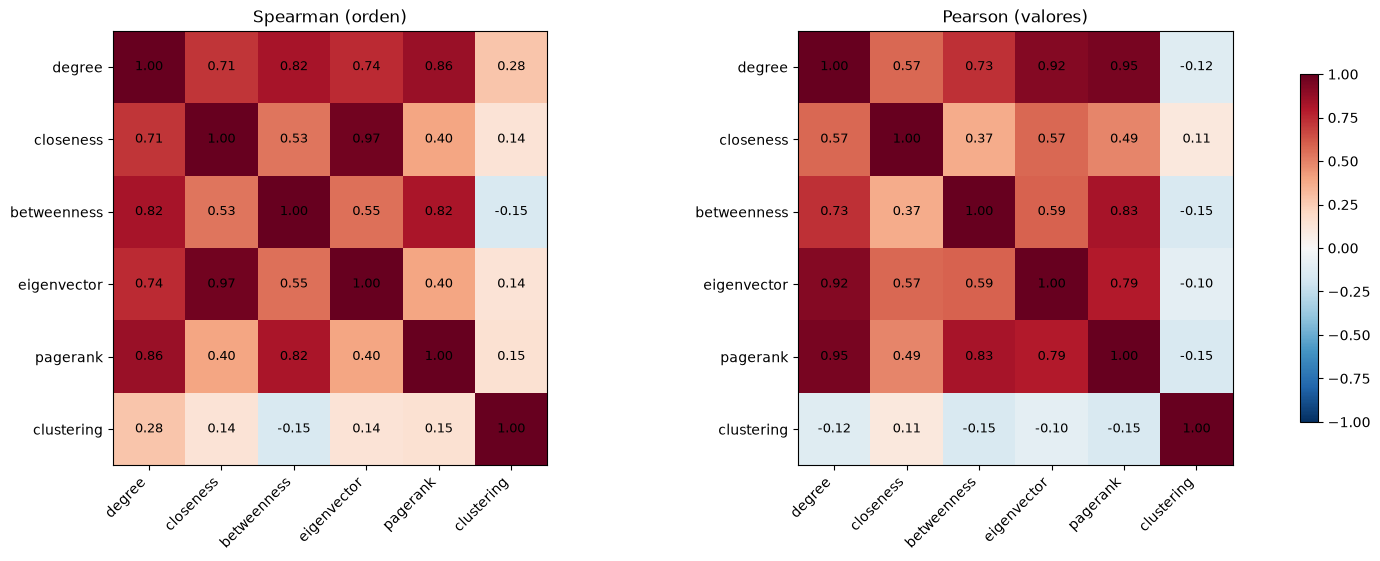

In [20]:
# 3.6 Correlación entre las seis medidas. Usamos dos tipos de correlación:
#  - Pearson: sensible a los valores extremos (los grandes hubs pesan mucho).
#  - Spearman: compara solo el orden de los aeropuertos en cada medida, así pesan todos por igual.
corr_s = df_nodos[medidas].corr(method="spearman")
corr_p = df_nodos[medidas].corr(method="pearson")

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
for eje, corr, titulo in zip(ejes, [corr_s, corr_p], ["Spearman (orden)", "Pearson (valores)"]):
    im = eje.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    eje.set_xticks(range(len(medidas))); eje.set_xticklabels(medidas, rotation=45, ha="right")
    eje.set_yticks(range(len(medidas))); eje.set_yticklabels(medidas)
    for i in range(len(medidas)):
        for j in range(len(medidas)):
            eje.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
    eje.set_title(titulo)
fig.colorbar(im, ax=ejes, shrink=0.8)
plt.show()

### Interpretación: ¿qué medidas coinciden y cuáles revelan actores distintos?

| Pareja | Spearman | Pearson | Lectura |
|---|---|---|---|
| closeness – eigenvector | **0,97** | 0,57 | Ordenan casi igual a toda la red: ambas miden cercanía al núcleo. |
| degree – pagerank | 0,86 | **0,95** | Coinciden: PageRank depende sobre todo del número de conexiones. |
| degree – eigenvector | 0,74 | **0,92** | Entre los grandes hubs coinciden mucho. |
| degree – betweenness | 0,82 | 0,73 | Relacionadas, pero con excepciones: los puentes. |
| betweenness – closeness | 0,53 | 0,37 | Es la medida que más información distinta aporta. |
| clustering – resto | −0,15 a 0,28 | −0,15 a 0,11 | Casi independiente: mide la agrupación local, no la centralidad. |

- **Pearson y Spearman cuentan historias distintas.** Pearson está dominado por unos pocos hubs gigantes, y entre ellos degree, eigenvector y PageRank se mueven juntos (0,92 a 0,95). Spearman compara el orden de los 3.214 aeropuertos, y ahí closeness y eigenvector son casi la misma medida (0,97).
- **No se puede reemplazar betweenness por degree.** Si solo miráramos degree, nos perderíamos a los puentes como ANC. Por eso, para la pregunta del proyecto, betweenness es la medida clave.
- **El clustering es otra dimensión.** Los aeropuertos con clustering alto son pequeños y pertenecen a grupos cerrados; no son centrales. Se usará en la sección 4 para entender comunidades.

# 4. Comunidades

Las centralidades miran a cada aeropuerto por separado. Una **comunidad** es un grupo de aeropuertos que se conectan mucho entre sí y poco con el resto. Detectarlas responde: **¿tiene la red grupos naturales y esos grupos reflejan algo que ya sabemos del mundo?**

## Qué vamos a hacer

| Paso | Qué hacemos | Para qué |
|---|---|---|
| **4.1 Detección** | Aplicamos dos algoritmos, Greedy modularity y Louvain, y comparamos número de comunidades y modularidad. Probamos la estabilidad de Louvain con 5 semillas. | Saber qué tan buena y qué tan estable es la partición. |
| **4.2 Caracterización** | Describimos las 5 comunidades más grandes: tamaño, aeropuertos centrales, países, densidad interna y conexiones hacia afuera. | Entender qué es cada grupo. |
| **4.3 Validación externa** | Contrastamos las comunidades con el atributo real (país) con una tabla de contingencia, NMI y ARI. | Ver si la estructura recupera lo que sabemos del mundo. |
| **4.4 Mapa interactivo** | Dibujamos la red sobre el mapa, coloreada por comunidad y con tamaño según degree. | Ver las comunidades de un vistazo. |
| **4.5 Hallazgos** | Cerramos con las conclusiones sobre comunidades. | Dejar claro qué aprendimos. |

## Decisiones de cálculo

- **Sin pesos:** igual que en las centralidades, para que todo sea comparable.
- **Modularidad:** mide qué tan separados están los grupos respecto de lo que se esperaría al azar. Valores sobre 0,3 indican estructura de comunidades clara.
- **Louvain es estocástico:** dos ejecuciones con semillas distintas pueden dar particiones algo diferentes. Fijamos `SEED` para que el resultado sea reproducible y verificamos la estabilidad con otras semillas.
- **Greedy modularity es determinista:** mismo resultado en cada ejecución.

In [21]:
# 4.1 Dos algoritmos de detección de comunidades, ambos sin pesos (weight=None).
com_greedy  = nx.community.greedy_modularity_communities(G, weight=None)      # determinista, tarda ~10 s
com_louvain = nx.community.louvain_communities(G, weight=None, seed=SEED)     # semilla fija: reproducible

def ordenar(comunidades):
    # De la más grande a la más chica: la comunidad 0 es siempre la mayor
    return sorted((set(c) for c in comunidades), key=len, reverse=True)
com_greedy, com_louvain = ordenar(com_greedy), ordenar(com_louvain)

# Etiqueta de comunidad de cada aeropuerto, guardada en df_nodos
def etiquetas(comunidades):
    return pd.Series({n: i for i, c in enumerate(comunidades) for n in c})
df_nodos["com_greedy"]  = etiquetas(com_greedy)
df_nodos["com_louvain"] = etiquetas(com_louvain)

resumen = pd.DataFrame({
    "Greedy modularity": [len(com_greedy), nx.community.modularity(G, com_greedy, weight=None),
                          len(com_greedy[0]), sum(len(c) < 5 for c in com_greedy)],
    "Louvain":           [len(com_louvain), nx.community.modularity(G, com_louvain, weight=None),
                          len(com_louvain[0]), sum(len(c) < 5 for c in com_louvain)],
}, index=["Número de comunidades", "Modularidad", "Tamaño de la comunidad mayor",
          "Comunidades con menos de 5 aeropuertos"])
display(resumen.round(4))

# Estabilidad de Louvain: lo repetimos con otras semillas
estabilidad = []
for s in [1, 7, 42, 123, 2024]:
    c = nx.community.louvain_communities(G, weight=None, seed=s)
    estabilidad.append({"semilla": s, "comunidades": len(c),
                        "modularidad": round(nx.community.modularity(G, c, weight=None), 4)})
display(pd.DataFrame(estabilidad).set_index("semilla"))

,Greedy modularity,Louvain
Número de comunidades,48.0000,27.0000
Modularidad,0.5988,0.6562
Tamaño de la comunidad mayor,963.0000,755.0000
Comunidades con menos de 5 aeropuertos,17.0000,7.0000


,comunidades,modularidad
semilla,,
1,24,0.6525
7,25,0.6587
42,27,0.6562
123,27,0.6536
2024,24,0.6589


In [22]:
# 4.2 Caracterización de las 5 comunidades más grandes de Louvain
def caracterizar(comunidades, k=5):
    filas = []
    for i, c in enumerate(comunidades[:k]):
        S = G.subgraph(c)
        hacia_afuera = sum(1 for u in c for v in G[u] if v not in c)     # rutas que salen de la comunidad
        top = df_nodos.loc[list(c)].sort_values("degree", ascending=False).head(3)["etiqueta"].tolist()
        paises = df_nodos.loc[list(c), "pais"].value_counts(normalize=True).head(3)
        filas.append({
            "comunidad": i,
            "tamaño": len(c),
            "aeropuertos más centrales": ", ".join(top),
            "países principales": ", ".join(f"{p} {v:.0%}" for p, v in paises.items()),
            "densidad interna": round(nx.density(S), 4),
            "aristas internas": S.number_of_edges(),
            "aristas hacia afuera": hacia_afuera,
        })
    return pd.DataFrame(filas).set_index("comunidad")

tabla_comunidades = caracterizar(com_louvain)
print(f"Las 5 mayores cubren {tabla_comunidades['tamaño'].sum()} de {len(df_nodos)} aeropuertos")
tabla_comunidades

Las 5 mayores cubren 2459 de 3214 aeropuertos


,tamaño,aeropuertos más centrales,países principales,densidad interna,aristas internas,aristas hacia afuera
comunidad,,,,,,
0,755,"ATL, ORD, DFW","United States 54%, Canada 12%, Mexico 7%",0.0146,4146,760
1,509,"AMS, FRA, CDG","France 11%, United Kingdom 9%, Spain 8%",0.0414,5346,1583
2,471,"ISL, DXB, BKK","India 14%, Iran 8%, Turkey 8%",0.0161,1781,1099
3,378,"SIN, KUL, SYD","Australia 30%, Indonesia 17%, Philippines 10%",0.0128,909,349
4,346,"PEK, PVG, CAN","China 50%, Japan 18%, Thailand 7%",0.0375,2237,619


In [23]:
# 4.3 Validación externa: ¿las comunidades recuperan el país del aeropuerto?
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

validacion = {}
for nombre, col in [("Greedy modularity", "com_greedy"), ("Louvain", "com_louvain")]:
    validacion[nombre] = {"NMI": normalized_mutual_info_score(df_nodos["pais"], df_nodos[col]),
                          "ARI": adjusted_rand_score(df_nodos["pais"], df_nodos[col])}
display(pd.DataFrame(validacion).round(4))

# Tabla de contingencia: 5 comunidades mayores (Louvain) x los 8 países con más aeropuertos
top_paises = df_nodos["pais"].value_counts().head(8).index
cont = pd.crosstab(df_nodos["com_louvain"], df_nodos["pais"])
display(cont.loc[range(5), top_paises])

# ¿Un país se queda junto o se reparte entre comunidades? (países con al menos 10 aeropuertos)
n_aero = df_nodos.groupby("pais").size()
pureza = df_nodos.groupby("pais")["com_louvain"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
grandes = n_aero[n_aero >= 10].index
print(f"Países con 10 aeropuertos o más: {len(grandes)}")
print(f"  con 80% o más de sus aeropuertos en una sola comunidad: {(pureza[grandes] >= 0.8).sum()}")
print("  los países más repartidos (fracción en su comunidad principal):",
      pureza[grandes].sort_values().head(5).round(2).to_dict())

,Greedy modularity,Louvain
NMI,0.5382,0.6286
ARI,0.1576,0.2897


pais,United States,Canada,China,Brazil,Australia,Russia,India,Indonesia
com_louvain,,,,,,,,
0,410,93,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,67,0
3,0,0,0,0,113,0,1,63
4,0,1,172,0,0,2,0,0


Países con 10 aeropuertos o más: 63
  con 80% o más de sus aeropuertos en una sola comunidad: 55
  los países más repartidos (fracción en su comunidad principal): {'Canada': 0.45, 'Congo (Kinshasa)': 0.5, 'Norway': 0.53, 'Ukraine': 0.54, 'Kenya': 0.62}


In [24]:
# 4.4 Mapa interactivo: cada aeropuerto en su posición geográfica real, coloreado por comunidad (Louvain)
# y con tamaño según su degree. Pasa el cursor sobre un punto para ver aeropuerto, ciudad y país.
import plotly.graph_objects as go
import plotly.express as px

lon = {n: G.nodes[n]["lon"] for n in G}
lat = {n: G.nodes[n]["lat"] for n in G}

# Rutas: una sola línea fina (los None separan una ruta de la siguiente)
ex, ey = [], []
for u, v in G.edges():
    ex += [lon[u], lon[v], None]
    ey += [lat[u], lat[v], None]

fig = go.Figure()
fig.add_trace(go.Scattergeo(lon=ex, lat=ey, mode="lines", hoverinfo="skip", showlegend=False,
                            line=dict(width=0.3, color="rgba(120,120,120,0.25)")))

def texto(sub):
    return (sub["etiqueta"] + " · " + sub["ciudad"] + ", " + sub["pais"]
            + " · degree " + sub["degree"].astype(str)).tolist()

paleta = px.colors.qualitative.Bold
N_COLOR = 8                                    # las 8 comunidades mayores tienen color propio
for i, c in enumerate(com_louvain[:N_COLOR]):
    sub = df_nodos.loc[sorted(c)]
    fig.add_trace(go.Scattergeo(
        lon=[lon[n] for n in sub.index], lat=[lat[n] for n in sub.index], mode="markers",
        name=f"Comunidad {i} ({len(c)})", text=texto(sub), hoverinfo="text",
        marker=dict(size=(3 + 1.2 * np.sqrt(sub["degree"])).tolist(), color=paleta[i],
                    opacity=0.85, line=dict(width=0.3, color="white"))))

# El resto de las comunidades se agrupa en gris
resto = sorted(n for c in com_louvain[N_COLOR:] for n in c)
sub = df_nodos.loc[resto]
fig.add_trace(go.Scattergeo(
    lon=[lon[n] for n in sub.index], lat=[lat[n] for n in sub.index], mode="markers",
    name=f"Otras comunidades ({len(resto)})", text=texto(sub), hoverinfo="text",
    marker=dict(size=(3 + 1.2 * np.sqrt(sub["degree"])).tolist(), color="lightgray",
                opacity=0.9, line=dict(width=0.3, color="white"))))

fig.update_geos(projection_type="natural earth", showland=True, landcolor="rgb(245,245,245)",
                showcountries=True, countrycolor="rgb(220,220,220)")
fig.update_layout(title="Red de rutas aéreas: comunidades (Louvain) sobre el mapa",
                  height=600, margin=dict(l=0, r=0, t=50, b=0))
fig.show()

In [25]:
# ¿Qué comunidades son más "abiertas"? Porcentaje de sus rutas que conectan con otras comunidades.
tabla_comunidades["% de rutas que salen"] = (
    100 * tabla_comunidades["aristas hacia afuera"]
    / (tabla_comunidades["aristas internas"] + tabla_comunidades["aristas hacia afuera"])
).round(1)
tabla_comunidades[["tamaño", "aeropuertos más centrales", "aristas internas", "aristas hacia afuera", "% de rutas que salen"]]

,tamaño,aeropuertos más centrales,aristas internas,aristas hacia afuera,% de rutas que salen
comunidad,,,,,
0,755,"ATL, ORD, DFW",4146,760,15.5
1,509,"AMS, FRA, CDG",5346,1583,22.8
2,471,"ISL, DXB, BKK",1781,1099,38.2
3,378,"SIN, KUL, SYD",909,349,27.7
4,346,"PEK, PVG, CAN",2237,619,21.7


### Cómo leer los resultados

- **Tabla de contingencia:** muestra solo las 5 comunidades mayores. Por eso países como Brasil y Rusia aparecen con ceros: sus aeropuertos pertenecen a comunidades más pequeñas.
- **NMI y ARI:** miden qué tanto coincide la partición con el país. El ARI castiga más que el NMI cuando los grupos tienen distinto nivel de detalle, y aquí hay 27 comunidades frente a 225 países.
- **Pureza por país:** para cada país con 10 aeropuertos o más, qué fracción de ellos cae en su comunidad principal. Responde directamente si la estructura respeta los países.

## 4.5 Hallazgos sobre las comunidades

1. **La red tiene comunidades claras.** La modularidad es 0,656 con Louvain y 0,599 con Greedy, muy por sobre el umbral de 0,3. Louvain separa mejor con menos grupos (27 frente a 48) y deja menos comunidades diminutas (7 frente a 17 con menos de 5 aeropuertos): Greedy tiende a fragmentar.

2. **El resultado es estable.** Con 5 semillas distintas Louvain entrega entre 24 y 27 comunidades y una modularidad entre 0,653 y 0,659. El número exacto de comunidades varía, la estructura no.

3. **Las comunidades son regiones del mundo.** Las 5 mayores cubren 2.459 de los 3.214 aeropuertos (76,5%): Norteamérica (755 aeropuertos; ATL, ORD, DFW; EE. UU. 54%, Canadá 12%, México 7%), Europa (509; AMS, FRA, CDG), un bloque con Turquía, Irán e India (471; ISL, DXB, BKK), Sudeste Asiático y Oceanía (378; SIN, KUL, SYD) y China y Asia oriental (346; PEK, PVG, CAN; China 50%, Japón 18%).

4. **La estructura respeta los países y los agrupa en regiones.** Louvain obtiene NMI 0,63 y ARI 0,29. El ARI es bajo porque una comunidad reúne varios países, no porque los países se partan: 55 de los 63 países con 10 aeropuertos o más (87%) tienen el 80% o más de sus aeropuertos en una sola comunidad. Los más repartidos son Canadá (45% en su comunidad principal), Congo (Kinshasa) (50%), Noruega (53%), Ucrania (54%) y Kenia (62%). Nuestra hipótesis es que son países extensos cuyos aeropuertos se conectan con vecinos distintos; queda por explorar.

5. **Algunas comunidades son mucho más abiertas que otras.** El 38,2% de las rutas de la comunidad 2 (ISL, DXB, BKK) sale hacia otras comunidades, frente a solo el 15,5% en Norteamérica. Europa es la que más rutas envía hacia afuera en cifras absolutas (1.583). Hipótesis para el Hito 2: los aeropuertos puente de la sección 3 están en estas fronteras entre comunidades, y lo contrastaremos con los roles estructurales y con el recomendador consciente de comunidad.

# 5. Roles estructurales

Una **comunidad** dice *con quién* se relaciona un aeropuerto; un **rol estructural** dice *cómo* se relaciona: si es un hub, un conector, un aeropuerto integrado a su grupo o un extremo de la red. Para descubrirlos agrupamos a los aeropuertos según su perfil de centralidad, con las técnicas de aprendizaje no supervisado del curso.

## Qué vamos a hacer

| Paso | Qué hacemos | Para qué |
|---|---|---|
| **5.1 Matriz de rasgos** | Siete medidas por aeropuerto (degree, closeness, betweenness, eigenvector, PageRank, clustering y excentricidad), transformadas y estandarizadas. | Que todas las medidas pesen por igual en el agrupamiento. |
| **5.2 ACP** | Reducimos las siete medidas a pocas componentes e interpretamos las cargas. | Ver cuántas dimensiones independientes tiene el perfil de un aeropuerto. |
| **5.3 k-means** | Elegimos k con el codo y el silhouette. | Decidir cuántos roles hay. |
| **5.4 Nombrar los roles** | Perfil de cada cluster (medianas) y los 5 aeropuertos más representativos. | Pasar de "cluster 3" a "hub", "terminal", etc., con evidencia. |
| **5.5 Segundo método** | GMM (pertenencias blandas) y DBSCAN (outliers estructurales), comparados con k-means. | Comprobar que los roles no dependen del algoritmo. |
| **5.6 Mapa ACP** | Los aeropuertos en las dos primeras componentes, coloreados por rol. | Ver los roles de un vistazo. |
| **5.7 Roles frente a comunidades** | Tabla de contingencia, ARI, NMI y el aeropuerto puente de cada comunidad. | Responder si cada comunidad tiene su propio puente y qué roles cruzan comunidades. |

## Decisiones

- **Se trabaja sobre la componente gigante** (3.188 aeropuertos), porque la excentricidad solo existe dentro de una componente conexa. Las medidas de centralidad son las de la sección 3.
- **Excentricidad:** la mayor distancia, en vuelos, entre el aeropuerto y cualquier otro. Mide qué tan lejos está del resto de la red.
- **Medidas de cola larga:** degree, betweenness, eigenvector y PageRank tienen unos pocos valores enormes y muchísimos pequeños. Sin transformarlas, los hubs dominarían todo el agrupamiento.
- **Semilla fija** en todos los algoritmos para que los resultados sean reproducibles.

In [26]:
# 5.1 Matriz de rasgos por aeropuerto, sobre la componente gigante (3.188 aeropuertos).
# La excentricidad (mayor distancia en vuelos a otro aeropuerto) solo existe dentro de una componente conexa.
excentricidad = pd.Series(nx.eccentricity(Gc), name="excentricidad")      # puede tardar unos segundos
medidas_rol = ["degree", "closeness", "betweenness", "eigenvector", "pagerank", "clustering", "excentricidad"]

df_rol = df_nodos.loc[list(Gc.nodes)].copy()
df_rol["excentricidad"] = excentricidad
X_crudo = df_rol[medidas_rol].astype(float)

# Medidas de cola larga: log(1 + x / mínimo positivo). Un log1p directo no sirve en betweenness, eigenvector
# y PageRank, porque sus valores son tan pequeños que el logaritmo quedaría casi lineal.
cola_larga = ["degree", "betweenness", "eigenvector", "pagerank"]
X = X_crudo.copy()
for m in cola_larga:
    minimo = X.loc[X[m] > 0, m].min()
    X[m] = np.log1p(X[m] / minimo)

# Asimetría de cada medida antes y después de la transformación (0 = simétrica)
display(pd.DataFrame({"antes": X_crudo.skew(), "después": X.skew()}).round(2).T)

# Estandarización: media 0 y desviación 1, para que ninguna medida domine por su escala
from sklearn.preprocessing import StandardScaler
Z = StandardScaler().fit_transform(X)
print("Matriz de rasgos estandarizada:", Z.shape)

,degree,closeness,betweenness,eigenvector,pagerank,clustering,excentricidad
antes,4.43,0.02,8.41,4.58,4.3,0.0,0.69
después,1.19,0.02,0.50,-1.22,1.5,0.0,0.69


Matriz de rasgos estandarizada: (3188, 7)


Varianza explicada por componente:
PC1    61.2%
PC2    19.7%
PC3    12.6%
PC4     3.1%
PC5     2.5%
PC6     0.6%
PC7     0.3%
Las dos primeras componentes explican el 80.9%


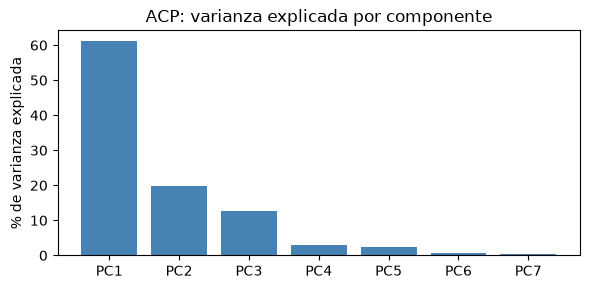

,PC1,PC2,PC3
degree,0.45,-0.19,0.24
closeness,0.44,0.25,-0.17
betweenness,0.38,-0.44,0.09
eigenvector,0.41,0.35,-0.22
pagerank,0.38,-0.41,0.31
clustering,0.03,0.53,0.82
excentricidad,-0.38,-0.36,0.29


In [27]:
# 5.2 ACP sobre la matriz estandarizada
from sklearn.decomposition import PCA
pca = PCA(random_state=SEED).fit(Z)

varianza = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i + 1}" for i in range(len(medidas_rol))])
print("Varianza explicada por componente:")
print((100 * varianza).round(1).astype(str).add("%").to_string())
print(f"Las dos primeras componentes explican el {100 * varianza.iloc[:2].sum():.1f}%")

fig, eje = plt.subplots(figsize=(6, 3))
eje.bar(varianza.index, 100 * varianza.values, color="steelblue")
eje.set_ylabel("% de varianza explicada")
eje.set_title("ACP: varianza explicada por componente")
plt.tight_layout()
plt.show()

# Cargas: cuánto aporta cada medida a cada componente
cargas = pd.DataFrame(pca.components_[:3].T, index=medidas_rol, columns=["PC1", "PC2", "PC3"])
cargas.round(2)

### Interpretación del ACP

- **Dos dimensiones explican casi todo:** PC1 reúne el 61,2% de la varianza y PC2 el 19,7%, es decir, el 80,9% entre las dos. Las siete medidas son redundantes entre sí y el perfil de un aeropuerto se resume en pocas dimensiones.
- **PC1 es "popularidad y cercanía":** degree (0,45), closeness (0,44), eigenvector (0,41), betweenness (0,38) y PageRank (0,38) cargan juntos con signo positivo, y la excentricidad lo hace con signo negativo (−0,38). Un aeropuerto con PC1 alto tiene muchas conexiones y está cerca de todos.
- **PC2 contrapone cohesión e intermediación:** el clustering (0,53), el eigenvector (0,35) y la closeness (0,25) cargan en positivo, mientras que betweenness (−0,44), PageRank (−0,41), excentricidad (−0,36) y degree (−0,19) cargan en negativo. Un PC2 alto indica un aeropuerto integrado a un grupo cerrado; un PC2 bajo, uno que intermedia entre grupos.
- **PC3 es casi solo clustering** (0,82) y explica el 12,6%.

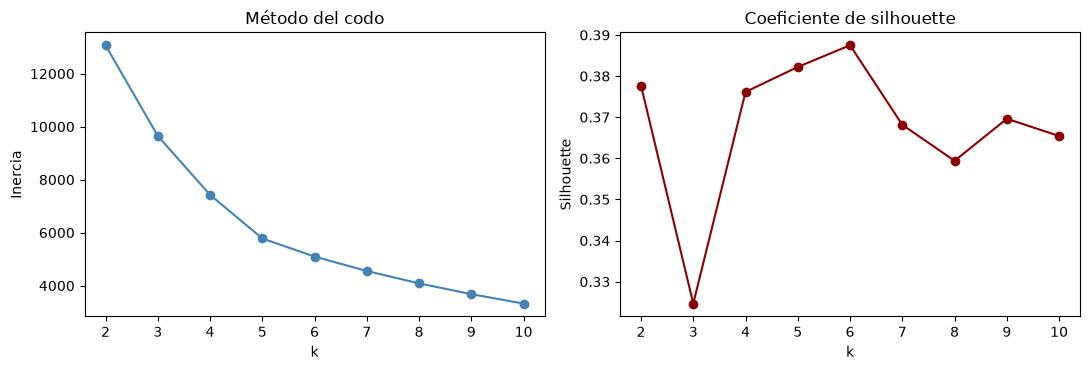

,inercia,silhouette
k,,
2,13070.776,0.378
3,9650.261,0.325
4,7426.281,0.376
5,5780.979,0.382
6,5095.857,0.388
7,4552.444,0.368
8,4085.208,0.359
9,3677.918,0.370
10,3322.617,0.365


In [28]:
# 5.3 k-means: elegimos el número de clusters k con el método del codo (inercia) y el coeficiente de silhouette
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
for k in range(2, 11):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    resultados.append({"k": k, "inercia": km_k.inertia_, "silhouette": silhouette_score(Z, km_k.labels_)})
res_k = pd.DataFrame(resultados).set_index("k")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].plot(res_k.index, res_k["inercia"], "o-", color="steelblue")
ejes[0].set_xlabel("k"); ejes[0].set_ylabel("Inercia"); ejes[0].set_title("Método del codo")
ejes[1].plot(res_k.index, res_k["silhouette"], "o-", color="darkred")
ejes[1].set_xlabel("k"); ejes[1].set_ylabel("Silhouette"); ejes[1].set_title("Coeficiente de silhouette")
plt.tight_layout()
plt.show()
res_k.round(3)

### Elección de k

El silhouette alcanza su máximo en **k = 6 (0,388)**, apenas por sobre k = 5 (0,382) y k = 2 (0,378). La inercia baja de forma gradual y no muestra un codo marcado, así que el codo no decide por sí solo. Como la diferencia entre k = 5 y k = 6 es mínima, desempatamos por interpretabilidad: con k = 6 los clusters tienen perfiles distintos que se pueden nombrar con evidencia (sección 5.4). Elegimos **k = 6**.

In [29]:
# 5.4 k-means final con k = 6 y nombre de cada rol
K = 6
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z)
df_rol["cluster"] = km.labels_

# Los números de cluster de k-means son arbitrarios. Los reordenamos de mayor a menor mediana de degree
# (y, si empatan, de mayor a menor closeness) para que el orden sea siempre el mismo.
orden = (df_rol.groupby("cluster")[["degree", "closeness"]].median()
                .sort_values(["degree", "closeness"], ascending=False).index.to_numpy())
df_rol["cluster"] = df_rol["cluster"].map({viejo: nuevo for nuevo, viejo in enumerate(orden)})
centroides = km.cluster_centers_[orden]            # centroides (en el espacio estandarizado) con el nuevo orden

# Nombres de los roles, asignados mirando el perfil de cada cluster (tabla de abajo)
nombres_rol = {0: "Hub", 1: "Integrado de comunidad", 2: "Periferia abierta",
               3: "Periferia cerrada", 4: "Periferia lejana", 5: "Terminal"}
df_rol["rol"] = df_rol["cluster"].map(nombres_rol)
roles_orden = list(nombres_rol.values())

# Perfil de cada rol: mediana de cada medida (en sus unidades originales) y número de aeropuertos
perfil = df_rol.groupby("rol")[medidas_rol].median().loc[roles_orden]
perfil.insert(0, "aeropuertos", df_rol["rol"].value_counts().loc[roles_orden])
display(perfil.round(3))

# Los 5 aeropuertos más representativos de cada rol: los más cercanos a su centroide
df_rol["dist_centroide"] = np.linalg.norm(Z - centroides[df_rol["cluster"].values], axis=1)
representativos = (df_rol.sort_values("dist_centroide").groupby("rol").head(5)
                         .assign(rol=lambda d: pd.Categorical(d["rol"], roles_orden))
                         .sort_values(["rol", "dist_centroide"]))
representativos[["rol", "etiqueta", "ciudad", "pais", "degree", "clustering"]].reset_index(drop=True)

,aeropuertos,degree,closeness,betweenness,eigenvector,pagerank,clustering,excentricidad
rol,,,,,,,,
Hub,394,48.0,0.315,0.002,0.028,0.001,0.303,8.0
Integrado de comunidad,653,9.0,0.287,0.000,0.005,0.000,0.639,8.0
Periferia abierta,353,4.0,0.244,0.000,0.000,0.000,0.400,9.0
Periferia cerrada,812,2.0,0.254,0.000,0.001,0.000,1.000,9.0
Periferia lejana,317,2.0,0.187,0.000,0.000,0.000,0.000,10.0
Terminal,659,1.0,0.244,0.000,0.000,0.000,0.000,9.0


,rol,etiqueta,ciudad,pais,degree,clustering
0,Hub,MCT,Muscat,Oman,54,0.370370
1,Hub,OVB,Novosibirsk,Russia,52,0.267722
2,Hub,DMM,Dammam,Saudi Arabia,47,0.365402
3,Hub,KWI,Kuwait,Kuwait,57,0.343985
4,Hub,SHE,Shenyang,China,61,0.330601
5,Integrado de comunidad,ADA,Adana,Turkey,10,0.600000
6,Integrado de comunidad,KAN,Kano,Nigeria,8,0.642857
7,Integrado de comunidad,LBB,Lubbock,United States,8,0.607143
8,Integrado de comunidad,LKO,Lucknow,India,9,0.666667
9,Integrado de comunidad,ROA,Roanoke VA,United States,9,0.583333


### Interpretación de los roles

Los nombres salen de la tabla de medianas, no del número de cluster:

| Rol | Aeropuertos | Perfil (medianas) | Lectura |
|---|---|---|---|
| **Hub** | 394 | degree 48, closeness 0,315, mayor betweenness y eigenvector, clustering 0,30 | Muchas conexiones cuyos destinos no se conectan entre sí. Es la zona de los conectores. |
| **Integrado de comunidad** | 653 | degree 9, clustering 0,64 | Aeropuertos medianos cuyos destinos están muy conectados entre sí: pertenecen a un grupo denso. |
| **Periferia abierta** | 353 | degree 4, clustering 0,40, excentricidad 9 | Pocas conexiones, que no forman un grupo cerrado. |
| **Periferia cerrada** | 812 | degree 2, clustering 1,0 | Dos vecinos que a su vez están conectados entre sí (un triángulo). |
| **Periferia lejana** | 317 | degree 2, closeness 0,187 (la menor), excentricidad 10 (la mayor) | Los más alejados del resto de la red (por ejemplo, aldeas de Alaska y Vanuatu). |
| **Terminal** | 659 | degree 1, clustering 0 | Una sola ruta: dependen de un único aeropuerto para estar conectados. |

Dos precisiones para no sobreinterpretar:

- Los representantes del rol Hub (Mascate, Novosibirsk, Kuwait, Shenyang) son **hubs regionales** con unos 50 destinos. Los grandes (Atlanta, Fráncfort, París) son los extremos de ese mismo cluster. k-means separa grados de conectividad, no distingue "hub grande" de "hub mediano".
- Los roles de periferia forman un continuo y sus fronteras son hasta cierto punto arbitrarias; lo robusto es la separación entre hubs, integrados y periferia.

In [30]:
# 5.5 Segundo método de agrupamiento: GMM (pertenencias blandas) y DBSCAN (outliers estructurales)
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# --- GMM con el mismo número de componentes: cada aeropuerto recibe una probabilidad de pertenecer a cada rol
gmm = GaussianMixture(n_components=K, covariance_type="full", n_init=3, random_state=SEED).fit(Z)
prob = gmm.predict_proba(Z)
df_rol["gmm"] = gmm.predict(Z)
print("GMM")
print(f"  ARI entre k-means y GMM: {adjusted_rand_score(df_rol['cluster'], df_rol['gmm']):.3f}")
print(f"  Aeropuertos con pertenencia máxima menor a 0,8 (roles ambiguos): {(prob.max(axis=1) < 0.8).sum()} de {len(df_rol)}")

# --- DBSCAN: los aeropuertos que no pertenecen a ninguna zona densa son outliers estructurales
# eps se elige mirando la distancia de cada aeropuerto a su décimo vecino más cercano
dist_vecino = NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)[0][:, -1]
EPS = 1.0
print("\nDBSCAN")
print(f"  eps = {EPS} equivale al percentil {100 * (dist_vecino <= EPS).mean():.0f} de la distancia al décimo vecino")
db = DBSCAN(eps=EPS, min_samples=10).fit(Z)
df_rol["dbscan"] = db.labels_
outliers = df_rol[df_rol["dbscan"] == -1]
print(f"  Clusters densos: {len(set(db.labels_)) - 1} | outliers: {len(outliers)} ({len(outliers) / len(df_rol):.1%})")
print("  Rol que k-means asigna a los outliers:", outliers["rol"].value_counts().to_dict())

outliers.sort_values("degree", ascending=False)[["etiqueta", "ciudad", "pais", "degree", "betweenness", "excentricidad", "rol"]].head(10)

GMM
  ARI entre k-means y GMM: 0.554
  Aeropuertos con pertenencia máxima menor a 0,8 (roles ambiguos): 2 de 3188

DBSCAN
  eps = 1.0 equivale al percentil 97 de la distancia al décimo vecino
  Clusters densos: 8 | outliers: 39 (1.2%)
  Rol que k-means asigna a los outliers: {'Periferia lejana': 24, 'Periferia cerrada': 5, 'Integrado de comunidad': 4, 'Periferia abierta': 3, 'Terminal': 2, 'Hub': 1}


,etiqueta,ciudad,pais,degree,betweenness,excentricidad,rol
id,,,,,,,
193,YYZ,Toronto,Canada,147,4.434537e-02,6,Hub
169,YXL,Sioux Lookout,Canada,18,7.634099e-03,8,Periferia abierta
120,YQR,Regina,Canada,9,0.000000e+00,7,Integrado de comunidad
166,YXE,Saskatoon,Canada,9,0.000000e+00,7,Integrado de comunidad
54,YEV,Inuvik,Canada,7,2.160788e-03,10,Periferia lejana
174,YXU,London,Canada,5,0.000000e+00,7,Integrado de comunidad
56,YFC,Fredericton,Canada,4,0.000000e+00,7,Periferia cerrada
5491,YFH,Fort Hope,Canada,3,9.258581e-04,8,Periferia abierta
91,YMO,Moosonee,Canada,3,2.489955e-03,8,Periferia abierta


### Qué muestran GMM y DBSCAN

- **GMM:** coincide en parte con k-means (ARI 0,554) y casi no deja aeropuertos ambiguos (solo 2 de 3.188 tienen una pertenencia máxima menor a 0,8). Es decir, los grupos están bien separados en este espacio; lo que cambia entre algoritmos son los límites entre los roles de periferia, que son un continuo.
- **DBSCAN** encuentra 8 zonas densas y marca **39 outliers estructurales (1,2%)**. Veinticuatro de ellos son "periferia lejana" para k-means. Entre los diez de mayor degree, ocho son aeropuertos canadienses (Toronto, Sioux Lookout, Regina, Saskatoon…) y dos son de Vanuatu. Toronto (degree 147) es el caso más llamativo: es un hub con una excentricidad de solo 6, la más baja del grupo, y su combinación de medidas no cabe en ninguna zona densa. Que tantos canadienses aparezcan aquí sugiere un perfil particular de esa región (conexiones moderadas y cercanas al núcleo), pero no lo hemos verificado.

In [31]:
# 5.6 Mapa de los aeropuertos en las dos primeras componentes del ACP, coloreado por rol
import plotly.express as px
import plotly.graph_objects as go

coords = pca.transform(Z)[:, :2]
df_rol["PC1"], df_rol["PC2"] = coords[:, 0], coords[:, 1]

fig = px.scatter(df_rol, x="PC1", y="PC2", color="rol", hover_name="etiqueta",
                 hover_data=["ciudad", "pais", "degree"], opacity=0.7,
                 category_orders={"rol": roles_orden}, title="Roles estructurales en el mapa del ACP")

# Centroides de cada rol (X negras)
cent_pca = pca.transform(centroides)[:, :2]
fig.add_trace(go.Scatter(x=cent_pca[:, 0], y=cent_pca[:, 1], mode="markers+text", text=roles_orden,
                         textposition="top center", name="Centroides", hoverinfo="skip",
                         marker=dict(symbol="x", size=12, color="black")))
fig.update_layout(height=600,
                  xaxis_title=f"PC1 ({varianza.iloc[0]:.0%}): popularidad y cercanía",
                  yaxis_title=f"PC2 ({varianza.iloc[1]:.0%}): cohesión (+) frente a intermediación (−)")
fig.show()

In [32]:
# 5.7 Roles frente a comunidades (Louvain)
# Tabla de contingencia: las 5 comunidades mayores y el resto agrupado
com_grupo = df_rol["com_louvain"].map(lambda c: str(c) if c < 5 else "otras")
cont = pd.crosstab(df_rol["rol"], com_grupo).loc[roles_orden, ["0", "1", "2", "3", "4", "otras"]]
display(cont)

print(f"ARI entre rol y comunidad: {adjusted_rand_score(df_rol['rol'], df_rol['com_louvain']):.3f}")
print(f"NMI entre rol y comunidad: {normalized_mutual_info_score(df_rol['rol'], df_rol['com_louvain']):.3f}")

# Fracción de vecinos de cada aeropuerto que pertenecen a otra comunidad, promedio por rol
com = df_nodos["com_louvain"].to_dict()
df_rol["vecinos_otra_comunidad"] = [np.mean([com[v] != com[n] for v in G[n]]) for n in df_rol.index]
display((100 * df_rol.groupby("rol")["vecinos_otra_comunidad"].mean().loc[roles_orden]).round(1)
        .rename("% de vecinos en otra comunidad").to_frame())

# ¿Cada comunidad tiene su propio puente? El aeropuerto de mayor betweenness de cada una de las 5 mayores
filas = []
for c in range(5):
    sub = df_rol[df_rol["com_louvain"] == c]
    n = sub["betweenness"].idxmax()
    filas.append({"comunidad": c, "aeropuerto": sub.loc[n, "etiqueta"], "ciudad": sub.loc[n, "ciudad"],
                  "rol": sub.loc[n, "rol"], "degree": int(sub.loc[n, "degree"]),
                  "betweenness": round(sub.loc[n, "betweenness"], 4),
                  "% de vecinos en otras comunidades": round(100 * sub.loc[n, "vecinos_otra_comunidad"])})
pd.DataFrame(filas).set_index("comunidad")

com_louvain,0,1,2,3,4,otras
rol,,,,,,
Hub,91,129,53,22,57,42
Integrado de comunidad,206,152,101,10,91,93
Periferia abierta,34,34,39,73,26,147
Periferia cerrada,210,90,162,114,94,142
Periferia lejana,3,5,6,102,4,197
Terminal,211,99,110,57,74,108


ARI entre rol y comunidad: 0.051
NMI entre rol y comunidad: 0.120


,% de vecinos en otra comunidad
rol,
Hub,15.4
Integrado de comunidad,6.4
Periferia abierta,4.9
Periferia cerrada,1.7
Periferia lejana,0.1
Terminal,0.3


,aeropuerto,ciudad,rol,degree,betweenness,% de vecinos en otras comunidades
comunidad,,,,,,
0,LAX,Los Angeles,Hub,148,0.0605,24
1,CDG,Paris,Hub,240,0.0636,47
2,DXB,Dubai,Hub,185,0.0554,49
3,SYD,Sydney,Hub,85,0.0348,26
4,PEK,Beijing,Hub,205,0.0498,34


### Interpretación: roles frente a comunidades

- **Los roles son casi independientes de las comunidades** (ARI 0,051; NMI 0,120). Cada comunidad grande contiene todos los roles: hubs, integrados, periferias y terminales. Las comunidades y los roles responden preguntas distintas (con quién me conecto frente a cómo me conecto), por eso aportan información complementaria para el recomendador.
- **El rol Hub es el que cruza fronteras:** en promedio, el 15,4% de los vecinos de un hub está en otra comunidad, frente al 1,7% en la periferia cerrada y 0,3% en los terminales.
- **Cada comunidad grande tiene su propio puente.** El aeropuerto de mayor betweenness de las cinco primeras comunidades es siempre un Hub: Los Ángeles, París CDG, Dubái, Sídney y Pekín. Entre el 24% y el 49% de sus vecinos están en otras comunidades; París y Dubái son los más "internacionales" (47% y 49%).
- **k-means no aísla a los puentes como un rol aparte:** quedan dentro del cluster Hub. Para identificarlos usamos la brecha entre betweenness y degree de la sección 3 ("tres formas de poder"), y no solo el cluster.
- **Implicación para la pregunta del proyecto:** los terminales (659 aeropuertos) dependen de un solo vecino y los hubs-puente concentran la intermediación. Ambos grupos son candidatos naturales para la simulación de la sección 8 y para dirigir las recomendaciones de rutas nuevas.

# 6. Recomendador de rutas

Con la estructura de la red ya descrita, la usamos para **sugerir rutas nuevas**: dado un aeropuerto, ¿a qué otros convendría conectarlo? Es un problema de *predicción de enlaces*: puntuamos todos los pares que hoy no tienen ruta directa y recomendamos los de mayor puntaje.

## Métodos

| Método | Idea | Puntaje del destino *v* para el origen *u* |
|---|---|---|
| **Vecinos comunes** | Dos aeropuertos con muchos destinos en común deberían conectarse. | cantidad de vecinos que comparten |
| **Jaccard** | Igual, pero corrige por tamaño: compartir 3 de 4 pesa más que 3 de 300. | compartidos / total de vecinos distintos |
| **Adamic–Adar** | Compartir un vecino *raro* dice más que compartir un hub. | suma de 1 / log(grado) de cada vecino compartido |
| **PageRank personalizado** | Un paseo aleatorio que parte en *u* y vuelve a *u* con probabilidad 0,15; *v* puntúa alto si el paseo suele pasar por él. Mira más allá de los vecinos directos. | probabilidad estacionaria del paseo |
| **Populares** (línea base) | Recomienda siempre los aeropuertos con más rutas. | grado de *v* |

## Variantes conscientes de comunidad

El puntaje se multiplica por (1 + λ) para los destinos que cumplen una condición de comunidad:

- **`dentro`** (cierre triádico): premia destinos de la **misma comunidad**. Densifica lo que ya existe.
- **`puentes`**: premia destinos de **otra comunidad**. Conecta grupos que hoy dependen de pocos intermediarios.

Con λ = 0 es el método original. En la sección 7 medimos qué se gana y qué se pierde con cada una.

## Qué devuelve `recomendar`

Para cada ruta sugerida: puntaje, **motivo** (vecinos en común y comunidad de destino), y si el destino salió del **respaldo de populares**. Se excluyen el propio aeropuerto y las rutas que ya existen.

**Arranque en frío:** un aeropuerto con 0 vecinos no tiene nada que puntuar, así que todas sus recomendaciones salen de los más populares (mayor degree). Si el método genera menos recomendaciones que las pedidas (por ejemplo, un aeropuerto en una componente diminuta), el resto se completa con populares y el motivo lo indica.

In [33]:
# 6.1 Puntajes de predicción de enlaces para un aeropuerto origen
from scipy import sparse

METODOS = ["vecinos_comunes", "jaccard", "adamic_adar", "ppr", "populares"]

def preparar(Gx, nodos):
    """Estructuras que usan todos los métodos para el grafo Gx (sin pesos), con el orden de nodos fijo."""
    M = nx.to_scipy_sparse_array(Gx, nodelist=nodos, weight=None, format="csr").astype(float)
    grado = np.asarray(M.sum(axis=1)).ravel()
    inv_log = np.where(grado > 1, 1.0 / np.log(np.maximum(grado, 2)), 0.0)      # 1/log(grado), para Adamic-Adar
    P = sparse.diags(1.0 / np.maximum(grado, 1)) @ M                            # matriz de transición del paseo aleatorio
    return {"M": M, "grado": grado, "inv_log": inv_log, "P": P.tocsr(),
            "nodos": nodos, "idx": {n: i for i, n in enumerate(nodos)}}

def puntajes(E, i, metodo, alfa=0.85, iteraciones=50):
    """Puntaje de TODOS los aeropuertos como destino candidato para el aeropuerto de índice i."""
    M, grado = E["M"], E["grado"]
    fila = M[[i], :]                                            # vecinos de i (fila de 1 x n)
    if metodo == "populares":
        return grado.copy()
    if metodo == "vecinos_comunes":
        return np.asarray((fila @ M).todense()).ravel()         # (A·A)[i, v] = vecinos compartidos
    if metodo == "jaccard":
        cn = np.asarray((fila @ M).todense()).ravel()
        union = grado[i] + grado - cn
        return np.divide(cn, union, out=np.zeros_like(cn), where=union > 0)
    if metodo == "adamic_adar":
        return np.asarray(((fila.multiply(E["inv_log"])) @ M).todense()).ravel()
    if metodo == "ppr":                                         # paseo aleatorio con reinicio en i
        e = np.zeros(len(grado)); e[i] = 1.0
        r = e.copy()
        for _ in range(iteraciones):
            r = (1 - alfa) * e + alfa * (E["P"].T @ r)
        return r
    raise ValueError(f"método desconocido: {metodo}")

In [41]:
# 6.2 Función recomendar(nodo, G, top, metodo)
info_aero = df_nodos[["etiqueta", "ciudad", "pais"]].loc[nodos]      # etiqueta, ciudad y país de cada aeropuerto
com_nodo = df_nodos["com_louvain"].to_dict()                         # comunidad Louvain de cada aeropuerto

def recomendar(nodo, Gx, top=10, metodo="ppr", comunidades=None, modo="ninguno", lam=0.0, E=None, info_nodos=None):
    """Recomienda `top` rutas nuevas para el aeropuerto `nodo` (código IATA o id numérico).
    metodo: vecinos_comunes, jaccard, adamic_adar, ppr o populares.
    modo: "ninguno", "dentro" (premia destinos de la MISMA comunidad: cierre triádico)
          o "puentes" (premia destinos de OTRA comunidad); lam es la fuerza del premio.
    Arranque en frío: con 0 vecinos todo sale de los más populares (mayor degree). Si el método genera
    menos de `top` recomendaciones, el resto se completa con populares."""
    nodos_g = list(Gx.nodes)
    E = E or preparar(Gx, nodos_g)
    info_nodos = info_aero if info_nodos is None else info_nodos
    comunidades = com_nodo if comunidades is None else comunidades
    if nodo not in E["idx"]:                                         # si llega un código IATA lo convertimos a id
        encontrado = info_nodos.index[info_nodos["etiqueta"] == nodo]
        if len(encontrado) == 0:
            raise KeyError(f"aeropuerto no encontrado: {nodo}")
        nodo = encontrado[0]
    i = E["idx"][nodo]
    indptr, indices = E["M"].indptr, E["M"].indices
    vecinos_i = indices[indptr[i]:indptr[i + 1]]
    com_arr = np.array([comunidades[n] for n in nodos_g])

    base = puntajes(E, i, metodo).astype(float)                      # puntaje del método
    s = base.copy()
    if modo != "ninguno" and lam > 0 and len(vecinos_i) > 0:
        mismo = com_arr == com_arr[i]
        s = s * (1 + lam * (mismo if modo == "dentro" else ~mismo))
    excluidos = np.zeros(len(nodos_g), dtype=bool)
    excluidos[i] = True                                              # no se recomienda a sí mismo
    excluidos[vecinos_i] = True                                      # ni rutas que ya tiene
    s[excluidos] = -np.inf

    # recomendaciones del método (solo con puntaje positivo); con 0 vecinos no hay ninguna
    del_metodo = [j for j in np.argsort(-s, kind="stable")[:top] if s[j] > 0] if len(vecinos_i) > 0 else []
    respaldo = []
    if len(del_metodo) < top:                                        # se completa con los más populares
        for j in np.argsort(-E["grado"], kind="stable"):
            if not excluidos[j] and j not in del_metodo:
                respaldo.append(j)
            if len(del_metodo) + len(respaldo) == top:
                break

    filas = []
    for j, es_respaldo in [(j, False) for j in del_metodo] + [(j, True) for j in respaldo]:
        comunes = np.intersect1d(vecinos_i, indices[indptr[j]:indptr[j + 1]])
        otra = com_arr[j] != com_arr[i]
        if es_respaldo:
            motivo = f"respaldo de populares ({int(E['grado'][j])} rutas)"
        elif len(comunes) > 0:
            nombres = [info_nodos.iloc[c]["etiqueta"] for c in comunes[np.argsort(-E["grado"][comunes])][:3]]
            motivo = f"{len(comunes)} vecino{'s' if len(comunes) > 1 else ''} en común ({', '.join(nombres)})"
        else:
            motivo = "sin vecinos en común (llega por paseo aleatorio)"
        motivo += " · otra comunidad" if otra else " · misma comunidad"
        filas.append({"etiqueta": info_nodos.iloc[j]["etiqueta"], "ciudad": info_nodos.iloc[j]["ciudad"],
                      "pais": info_nodos.iloc[j]["pais"], "metodo": "populares" if es_respaldo else metodo,
                      "puntaje": E["grado"][j] if es_respaldo else base[j], "comunidad_destino": int(com_arr[j]),
                      "vecinos_comunes": len(comunes), "otra_comunidad": bool(otra),
                      "respaldo": es_respaldo, "motivo": motivo})
    return pd.DataFrame(filas)

E_G = preparar(G, nodos)        # estructuras del grafo completo, se reutilizan en las celdas siguientes
recomendar("SCL", G, top=5, metodo="ppr", E=E_G)[["etiqueta", "ciudad", "puntaje", "comunidad_destino", "motivo"]]

,etiqueta,ciudad,puntaje,comunidad_destino,motivo
0,LPB,La Paz,0.004984,5,"5 vecinos en común (MIA, BOG, LIM) · misma com..."
1,IAH,Houston,0.004814,0,"15 vecinos en común (CDG, ATL, DFW) · otra com..."
2,ORD,Chicago,0.003860,0,"12 vecinos en común (CDG, ATL, DFW) · otra com..."
3,AMS,Amsterdam,0.003726,1,"17 vecinos en común (CDG, ATL, DFW) · otra com..."
4,RGL,Rio Gallegos,0.003564,5,"2 vecinos en común (AEP, PUQ) · misma comunidad"


In [42]:
# 6.3 Validación: nuestros puntajes deben coincidir con los de NetworkX
import random
random.seed(SEED)
pares = []
while len(pares) < 300:                                   # 300 pares de aeropuertos SIN ruta directa
    u, v = random.sample(nodos, 2)
    if not G.has_edge(u, v):
        pares.append((u, v))

nx_jac = {(u, v): p for u, v, p in nx.jaccard_coefficient(G, pares)}
nx_aa  = {(u, v): p for u, v, p in nx.adamic_adar_index(G, pares)}
dif_cn  = max(abs(puntajes(E_G, E_G["idx"][u], "vecinos_comunes")[E_G["idx"][v]] - len(list(nx.common_neighbors(G, u, v)))) for u, v in pares)
dif_jac = max(abs(puntajes(E_G, E_G["idx"][u], "jaccard")[E_G["idx"][v]] - nx_jac[(u, v)]) for u, v in pares)
dif_aa  = max(abs(puntajes(E_G, E_G["idx"][u], "adamic_adar")[E_G["idx"][v]] - nx_aa[(u, v)]) for u, v in pares)

# PageRank personalizado: comparamos con nx.pagerank desde un aeropuerto de ejemplo
origen = nodos[10]
ref = nx.pagerank(G, alpha=0.85, personalization={origen: 1}, weight=None, tol=1e-12)
mio = puntajes(E_G, E_G["idx"][origen], "ppr")
dif_ppr = max(abs(mio[E_G["idx"][n]] - ref[n]) for n in nodos)

print("Diferencia máxima con NetworkX en 300 pares:")
print(f"  vecinos comunes: {dif_cn:.1e} | Jaccard: {dif_jac:.1e} | Adamic-Adar: {dif_aa:.1e}")
print(f"PageRank personalizado (50 iteraciones) en todos los nodos: {dif_ppr:.1e}")

Diferencia máxima con NetworkX en 300 pares:
  vecinos comunes: 0.0e+00 | Jaccard: 0.0e+00 | Adamic-Adar: 2.2e-16
PageRank personalizado (50 iteraciones) en todos los nodos: 4.5e-07


In [43]:
# 6.4 Demostración. Un aeropuerto de cada rol estructural (el más representativo de la sección 5.4)
casos = {rol: representativos[representativos["rol"] == rol].iloc[0]["etiqueta"] for rol in roles_orden}
for rol, codigo in casos.items():
    n_ = df_nodos.index[df_nodos["etiqueta"] == codigo][0]
    print(f"\n[{rol}] {codigo} ({df_nodos.loc[n_, 'ciudad']}): {int(E_G['grado'][E_G['idx'][n_]])} rutas, comunidad {com_nodo[n_]}")
    display(recomendar(codigo, G, 5, "ppr", E=E_G)[["etiqueta", "ciudad", "puntaje", "comunidad_destino", "motivo"]])

# Arranque en frío (1): PUQ al que le quitamos todas sus rutas (0 vecinos)
nodo_puq = df_nodos.index[df_nodos["etiqueta"] == "PUQ"][0]
G_frio = G.copy()
G_frio.remove_edges_from(list(G.edges(nodo_puq)))
print("\n[Arranque en frío] PUQ sin ninguna ruta")
display(recomendar("PUQ", G_frio, 5, "ppr")[["etiqueta", "ciudad", "puntaje", "respaldo", "motivo"]])

# Arranque en frío (2): un aeropuerto real de la componente más pequeña, donde el método casi no tiene candidatos
chico = next(iter(min(nx.connected_components(G), key=len)))
print(f"\n[Arranque en frío] {df_nodos.loc[chico, 'etiqueta']} ({df_nodos.loc[chico, 'ciudad']}), en una componente de {len(min(nx.connected_components(G), key=len))} aeropuertos")
display(recomendar(chico, G, 5, "ppr", E=E_G)[["etiqueta", "ciudad", "puntaje", "respaldo", "motivo"]])

# Variantes conscientes de comunidad para un hub (SCL)
print("\nSCL con PageRank personalizado, 10 recomendaciones:")
for modo, lam in [("ninguno", 0), ("dentro", 1.0), ("puentes", 1.0)]:
    r = recomendar("SCL", G, 10, "ppr", modo=modo, lam=lam, E=E_G)
    print(f"  {modo:8s} (λ={lam}): {r['otra_comunidad'].sum()} de 10 en otra comunidad -> {list(r['etiqueta'])}")


[Hub] MCT (Muscat): 54 rutas, comunidad 2


,etiqueta,ciudad,puntaje,comunidad_destino,motivo
0,AMS,Amsterdam,0.004386,1,"20 vecinos en común (FRA, CDG, ISL) · otra com..."
1,SIN,Singapore,0.004283,3,"25 vecinos en común (FRA, CDG, ISL) · otra com..."
2,DME,Moscow,0.003784,6,"14 vecinos en común (FRA, MUC, DXB) · otra com..."
3,MHD,Mashhad,0.003687,2,"13 vecinos en común (ISL, DXB, DOH) · misma co..."
4,PEK,Beijing,0.003589,4,"19 vecinos en común (FRA, CDG, ISL) · otra com..."



[Integrado de comunidad] ADA (Adana): 10 rutas, comunidad 2


,etiqueta,ciudad,puntaje,comunidad_destino,motivo
0,FRA,Frankfurt,0.006976,1,"7 vecinos en común (ISL, JED, SAW) · otra comu..."
1,AMS,Amsterdam,0.006459,1,"5 vecinos en común (ISL, SAW, AYT) · otra comu..."
2,MUC,Munich,0.006378,1,"6 vecinos en común (ISL, SAW, AYT) · otra comu..."
3,VIE,Vienna,0.005519,1,"6 vecinos en común (ISL, SAW, AYT) · otra comu..."
4,DXB,Dubai,0.005489,2,"4 vecinos en común (ISL, JED, SAW) · misma com..."



[Periferia abierta] LRE (Longreach): 4 rutas, comunidad 3


,etiqueta,ciudad,puntaje,comunidad_destino,motivo
0,TSV,Townsville,0.027112,3,"2 vecinos en común (BNE, WIN) · misma comunidad"
1,SYD,Sydney,0.021062,3,1 vecino en común (BNE) · misma comunidad
2,MEL,Melbourne,0.013717,3,1 vecino en común (BNE) · misma comunidad
3,CNS,Cairns,0.009632,3,1 vecino en común (BNE) · misma comunidad
4,AKL,Auckland,0.008805,3,1 vecino en común (BNE) · misma comunidad


... (7 outputs left out)

,etiqueta,ciudad,puntaje,respaldo,motivo
0,AMS,Amsterdam,248.0,True,respaldo de populares (248 rutas) · otra comun...
1,FRA,Frankfurt,244.0,True,respaldo de populares (244 rutas) · otra comun...
2,CDG,Paris,240.0,True,respaldo de populares (240 rutas) · otra comun...
3,ISL,Istanbul,233.0,True,respaldo de populares (233 rutas) · otra comun...
4,ATL,Atlanta,217.0,True,respaldo de populares (217 rutas) · otra comun...



[Arranque en frío] YWH (Victoria), en una componente de 2 aeropuertos


,etiqueta,ciudad,puntaje,respaldo,motivo
0,AMS,Amsterdam,248.0,True,respaldo de populares (248 rutas) · otra comun...
1,FRA,Frankfurt,244.0,True,respaldo de populares (244 rutas) · otra comun...
2,CDG,Paris,240.0,True,respaldo de populares (240 rutas) · otra comun...
3,ISL,Istanbul,233.0,True,respaldo de populares (233 rutas) · otra comun...
4,ATL,Atlanta,217.0,True,respaldo de populares (217 rutas) · otra comun...



SCL con PageRank personalizado, 10 recomendaciones:
  ninguno  (λ=0): 8 de 10 en otra comunidad -> ['LPB', 'IAH', 'ORD', 'AMS', 'RGL', 'EWR', 'FRA', 'LAX', 'CLT', 'PPT']
  dentro   (λ=1.0): 1 de 10 en otra comunidad -> ['LPB', 'RGL', 'VCP', 'VVI', 'BSB', 'POA', 'CNF', 'CWB', 'IAH', 'BRC']
  puentes  (λ=1.0): 10 de 10 en otra comunidad -> ['IAH', 'ORD', 'AMS', 'EWR', 'FRA', 'LAX', 'CLT', 'PPT', 'DEN', 'DTW']


### Cómo leer los resultados

- **Validación:** los cuatro puntajes coinciden con NetworkX (diferencias del orden de 10⁻¹⁶ a 10⁻⁷). El recomendador calcula lo que dice calcular.
- **Un aeropuerto de cada rol:** las recomendaciones respetan el entorno de cada uno. Mascate (Hub) recibe otros hubs (Ámsterdam, Singapur, Moscú, Pekín), casi todos de otra comunidad. Los aeropuertos pequeños reciben destinos de su propia región: Tanjung Pinang (Terminal, una sola ruta) recibe Kuala Lumpur, Singapur y Batam, todos por su único vecino (Yakarta); Elim (Periferia lejana, Alaska) recibe aeropuertos vecinos como Unalakleet y Shaktoolik, y Anchorage.
- **El motivo es verificable:** cada fila dice cuántos vecinos comparte el destino con el origen y cuáles son (por ejemplo, "15 vecinos en común (CDG, ATL, DFW)"), más si el destino está en otra comunidad.
- **Arranque en frío:** PUQ sin ninguna ruta, y un aeropuerto real de una componente de solo 2 aeropuertos (YWH), reciben los más populares (Ámsterdam, Fráncfort, París…) con el motivo "respaldo de populares". Es la única opción honesta cuando no hay vecinos desde donde puntuar.
- **Las dos variantes en SCL:** con el método base, 8 de las 10 recomendaciones van a otra comunidad. Con `dentro` (λ = 1) baja a 1 de 10 y la lista se llena de ciudades sudamericanas (La Paz, Río Gallegos, Viracopos, Santa Cruz, Brasilia). Con `puentes` (λ = 1) sube a 10 de 10 (Houston, Chicago, Ámsterdam, Newark, Fráncfort).

### ¿Cuándo conviene cada variante?

| Variante | Qué hace | Conviene cuando |
|---|---|---|
| **`dentro`** (cierre triádico) | Si A llega a B y C, propone conectar B con C. Densifica el grupo. | El objetivo es dar más oferta y redundancia local en una región que ya funciona. |
| **`puentes`** | Premia destinos de otras comunidades. | El objetivo es conectar grupos que hoy dependen de pocos intermediarios, que es el caso de **nuestra pregunta**. |

En la sección 8 comprobamos que, para reducir la dependencia, ni siquiera `puentes` basta si los destinos son los hubs de siempre.

# 7. Evaluación offline del recomendador

¿Qué tan bien recomienda? No tenemos usuarios reales, así que hacemos una **prueba de ocultamiento**: escondemos una parte de las rutas existentes, recomendamos usando solo las demás y vemos si las rutas escondidas aparecen entre las recomendaciones.

## Protocolo

1. **Se oculta el 20% de las rutas** (3.772 de 18.858), al azar. Nunca se ocultan las rutas de un *bosque generador* de la red, así que el grafo de entrenamiento conserva las mismas componentes conexas y ningún aeropuerto queda aislado.
2. **Se recomienda con el grafo de entrenamiento.** Los puntajes y las comunidades se calculan solo con ese grafo, para no filtrar información de las rutas ocultas.
3. **Se repite con 5 particiones distintas** (semillas 42 a 46) y se reporta el promedio y la desviación estándar.

## Métricas

| Métrica | Qué mide |
|---|---|
| **HitRate@N** (N = 1, 3, 5, 10) | Para cada ruta oculta (u, v), contada en los dos sentidos: ¿aparece v entre las N primeras recomendaciones de u? Es la fracción de rutas ocultas recuperadas. |
| **AUC** | Probabilidad de que una ruta oculta tenga mayor puntaje que un par sin ruta elegido al azar (se usan tantos pares al azar como rutas ocultas). 0,5 equivale a azar y 1 a perfección. |
| **Cobertura@10** | Fracción de los 3.214 aeropuertos que aparece al menos una vez en algún top 10. |
| **Novedad@10** | Fracción de las recomendaciones que llevan a **otra comunidad**. |
| **HitRate@10 cruzadas** | HitRate@10 contando solo las rutas ocultas que unen comunidades distintas (cerca del 15% de las rutas). Prueba si el recomendador encuentra los puentes. |
| **HitRate@10 grado ≤ 1** | HitRate@10 solo para aeropuertos que quedaron con 0 o 1 ruta en el entrenamiento: el caso de arranque en frío. |

## Qué comparamos

Azar y populares (líneas base); vecinos comunes, Jaccard, Adamic–Adar y PageRank personalizado; y las variantes conscientes de comunidad `dentro` y `puentes`.

**Advertencia de lectura:** un "acierto" significa recuperar una ruta que *ya existía* en los datos (de 2014). No mide demanda ni rentabilidad, y una recomendación que no acierta no es necesariamente mala. Cada aeropuerto tiene en promedio 5 rutas ocultas y solo se muestran 10 recomendaciones, así que los HitRate absolutos son bajos por construcción; lo que importa es la comparación entre métodos.

In [44]:
# 7.1 Partición de aristas: ocultamos el 20% de las rutas sin desconectar la red
def partir_aristas(Gx, frac=0.2, seed=42):
    """Oculta `frac` de las aristas. El bosque generador (spanning forest) nunca se oculta,
    así que el grafo de entrenamiento mantiene las mismas componentes y ningún aeropuerto queda aislado."""
    rng = np.random.default_rng(seed)
    bosque = {frozenset(e) for e in nx.minimum_spanning_edges(Gx, weight=None, data=False)}
    candidatas = [e for e in Gx.edges() if frozenset(e) not in bosque]
    n_ocultar = int(round(frac * Gx.number_of_edges()))
    elegidas = rng.choice(len(candidatas), size=n_ocultar, replace=False)
    ocultas = [candidatas[k] for k in elegidas]
    Gtr = Gx.copy()
    Gtr.remove_edges_from(ocultas)
    return Gtr, ocultas

# Comprobación con la primera partición
Gtr, ocultas = partir_aristas(G, 0.2, SEED)
print(f"Rutas ocultas: {len(ocultas)} de {G.number_of_edges()} ({len(ocultas) / G.number_of_edges():.0%})")
print(f"Componentes conexas: {nx.number_connected_components(G)} en la red completa y {nx.number_connected_components(Gtr)} en entrenamiento")
print(f"Menor grado en entrenamiento: {min(dict(Gtr.degree()).values())} (ningún aeropuerto queda aislado)")

Rutas ocultas: 3772 de 18858 (20%)
Componentes conexas: 7 en la red completa y 7 en entrenamiento
Menor grado en entrenamiento: 1 (ningún aeropuerto queda aislado)


In [45]:
# 7.2 Función de evaluación: recomienda sobre el grafo de entrenamiento y mide las métricas
NS = [1, 3, 5, 10]

def evaluar(Gx, nodos, seed, variantes, frac=0.2):
    """variantes: lista de (nombre, metodo, modo, lam). Devuelve una fila de métricas por variante."""
    Gtr, ocultas = partir_aristas(Gx, frac, seed)
    E = preparar(Gtr, nodos)
    n = len(nodos)
    com = np.zeros(n, dtype=int)                       # comunidades calculadas SOLO con el grafo de entrenamiento
    for k, c in enumerate(nx.community.louvain_communities(Gtr, seed=seed, weight=None)):
        for nodo in c:
            com[E["idx"][nodo]] = k
    ocultos = {}                                       # rutas ocultas por aeropuerto (cada ruta cuenta en los dos sentidos)
    for u, v in ocultas:
        iu, iv = E["idx"][u], E["idx"][v]
        ocultos.setdefault(iu, set()).add(iv)
        ocultos.setdefault(iv, set()).add(iu)
    n_pares = sum(len(v) for v in ocultos.values())                       # 2 x rutas ocultas
    n_cruz = sum(int(com[j] != com[i]) for i, vs in ocultos.items() for j in vs)
    n_frio = sum(len(vs) for i, vs in ocultos.items() if E["grado"][i] <= 1)
    # pares (ruta oculta, par sin ruta al azar del mismo origen) para el AUC: misma cantidad que rutas ocultas
    rng = np.random.default_rng(seed)
    Mfull = nx.to_scipy_sparse_array(Gx, nodelist=nodos, weight=None, format="csr")
    pares_auc = {}
    for u, v in ocultas:
        a, b = (E["idx"][u], E["idx"][v]) if rng.random() < 0.5 else (E["idx"][v], E["idx"][u])
        while True:
            w = int(rng.integers(n))
            if w != a and Mfull[a, w] == 0:
                break
        pares_auc.setdefault(a, []).append((b, w))

    filas = []
    for nombre, metodo, modo, lam in variantes:
        aciertos = {k: 0 for k in NS}
        acierto_cruz = acierto_frio = 0
        recomendados = np.zeros(n, dtype=bool)
        otra_com, total_rec = 0, 0
        auc_gana, auc_total = 0.0, 0
        rng_azar = np.random.default_rng(seed + 1)
        for i in sorted(ocultos):
            s = rng_azar.random(n) if metodo == "azar" else puntajes(E, i, metodo).astype(float)
            if modo != "ninguno" and lam > 0:
                s = s * (1 + lam * ((com == com[i]) if modo == "dentro" else (com != com[i])))
            for b, w in pares_auc.get(i, []):                       # AUC con los puntajes del origen
                auc_total += 1
                auc_gana += 1.0 if s[b] > s[w] else (0.5 if s[b] == s[w] else 0.0)
            s[i] = -np.inf                                          # no se recomienda a sí mismo
            s[E["M"].indices[E["M"].indptr[i]:E["M"].indptr[i + 1]]] = -np.inf   # ni rutas que ya tiene
            top = np.argpartition(-s, 10)[:10]
            top = top[np.argsort(-s[top], kind="stable")]
            for k in NS:                                            # HitRate: ¿aparece el destino oculto entre las N primeras?
                aciertos[k] += len(ocultos[i] & set(top[:k]))
            hit10 = ocultos[i] & set(top)
            acierto_cruz += sum(com[j] != com[i] for j in hit10)
            if E["grado"][i] <= 1:
                acierto_frio += len(hit10)
            recomendados[top] = True
            otra_com += (com[top] != com[i]).sum()
            total_rec += 10
        fila = {"variante": nombre, "split": seed}
        for k in NS:
            fila[f"HitRate@{k}"] = aciertos[k] / n_pares
        fila["HitRate@10 cruzadas"] = acierto_cruz / n_cruz
        fila["HitRate@10 grado<=1"] = acierto_frio / n_frio
        fila["AUC"] = auc_gana / auc_total
        fila["cobertura@10"] = recomendados.sum() / n
        fila["novedad@10"] = otra_com / total_rec
        fila["frac_cruzan"] = n_cruz / n_pares
        fila["rutas_ocultas"] = len(ocultas)
        fila["aeropuertos_test"] = len(ocultos)
        filas.append(fila)
    return pd.DataFrame(filas)

In [46]:
# 7.3 Evaluación completa: 11 variantes x 5 particiones (tarda unos 2 minutos)
variantes = [("azar", "azar", "ninguno", 0), ("populares", "populares", "ninguno", 0),
             ("vecinos_comunes", "vecinos_comunes", "ninguno", 0), ("jaccard", "jaccard", "ninguno", 0),
             ("adamic_adar", "adamic_adar", "ninguno", 0), ("ppr", "ppr", "ninguno", 0),
             ("ppr + dentro (λ=0.5)", "ppr", "dentro", 0.5), ("ppr + dentro (λ=1)", "ppr", "dentro", 1.0),
             ("ppr + puentes (λ=0.25)", "ppr", "puentes", 0.25), ("ppr + puentes (λ=0.5)", "ppr", "puentes", 0.5),
             ("ppr + puentes (λ=1)", "ppr", "puentes", 1.0)]

resultados_eval = pd.concat([evaluar(G, nodos, semilla, variantes) for semilla in range(SEED, SEED + 5)], ignore_index=True)

metricas = ["HitRate@1", "HitRate@3", "HitRate@5", "HitRate@10", "HitRate@10 cruzadas", "HitRate@10 grado<=1",
            "AUC", "cobertura@10", "novedad@10"]
media = resultados_eval.groupby("variante", sort=False)[metricas].mean()
desv  = resultados_eval.groupby("variante", sort=False)[metricas].std()
print(f"Rutas ocultas por partición: {int(resultados_eval['rutas_ocultas'].mean())} | aeropuertos con rutas ocultas: {resultados_eval['aeropuertos_test'].min()} a {resultados_eval['aeropuertos_test'].max()}")
print(f"% de rutas ocultas que cruzan comunidades: {100 * resultados_eval['frac_cruzan'].mean():.1f}%")
print("\nPromedio de las 5 particiones:")
display(media.round(3))
print("Desviación estándar entre particiones (máximo por columna):")
display(desv.max().round(3).to_frame("desv. estándar máx.").T)

Rutas ocultas por partición: 3772 | aeropuertos con rutas ocultas: 1474 a 1524
% de rutas ocultas que cruzan comunidades: 15.4%

Promedio de las 5 particiones:


,HitRate@1,HitRate@3,HitRate@5,HitRate@10,HitRate@10 cruzadas,HitRate@10 grado<=1,AUC,cobertura@10,novedad@10
variante,,,,,,,,,
azar,0.000,0.001,0.002,0.004,0.003,0.003,0.496,0.992,0.864
populares,0.015,0.032,0.042,0.082,0.207,0.018,0.876,0.012,0.856
vecinos_comunes,0.055,0.134,0.194,0.305,0.237,0.297,0.964,0.515,0.183
jaccard,0.037,0.091,0.133,0.217,0.106,0.398,0.959,0.836,0.079
adamic_adar,0.061,0.147,0.211,0.325,0.230,0.297,0.966,0.554,0.162
ppr,0.081,0.175,0.243,0.359,0.239,0.434,0.982,0.349,0.153
ppr + dentro (λ=0.5),0.081,0.177,0.246,0.363,0.145,0.447,0.984,0.370,0.068
ppr + dentro (λ=1),0.080,0.176,0.245,0.362,0.095,0.447,0.984,0.378,0.036
ppr + puentes (λ=0.25),0.077,0.170,0.236,0.351,0.296,0.412,0.980,0.338,0.222


Desviación estándar entre particiones (máximo por columna):


,HitRate@1,HitRate@3,HitRate@5,HitRate@10,HitRate@10 cruzadas,HitRate@10 grado<=1,AUC,cobertura@10,novedad@10
desv. estándar máx.,0.003,0.005,0.004,0.005,0.016,0.047,0.006,0.006,0.013


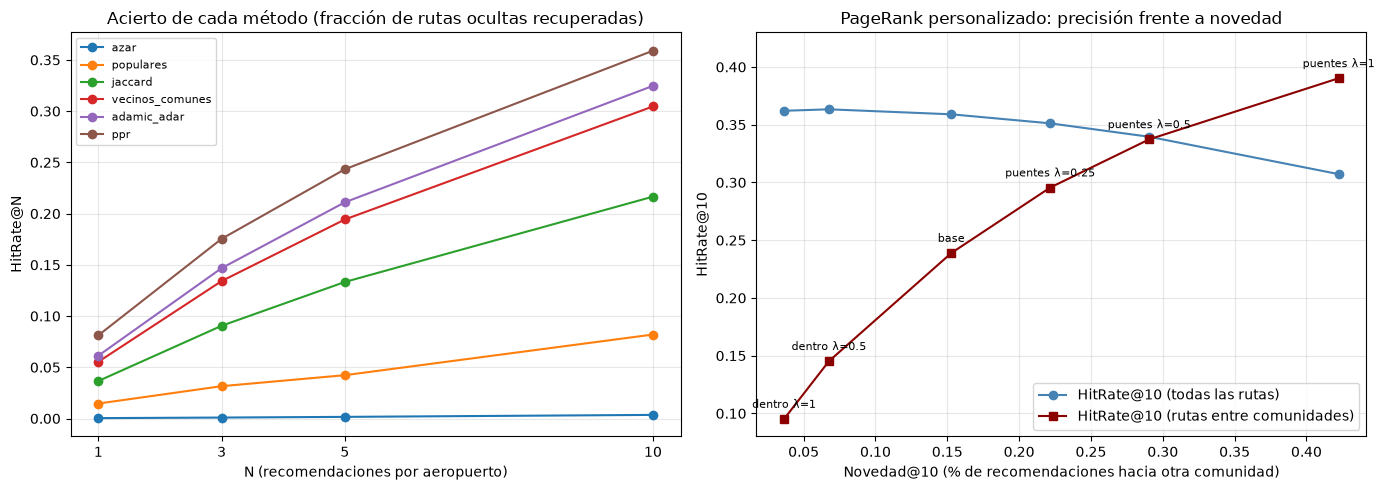

In [47]:
# 7.4 Gráficos: HitRate@N por método y compromiso entre acierto y novedad
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

for nombre in ["azar", "populares", "jaccard", "vecinos_comunes", "adamic_adar", "ppr"]:
    ejes[0].plot(NS, [media.loc[nombre, f"HitRate@{k}"] for k in NS], "o-", label=nombre)
ejes[0].set_xticks(NS); ejes[0].set_xlabel("N (recomendaciones por aeropuerto)"); ejes[0].set_ylabel("HitRate@N")
ejes[0].set_title("Acierto de cada método (fracción de rutas ocultas recuperadas)")
ejes[0].legend(loc="upper left", fontsize=8); ejes[0].grid(alpha=0.3)

# De "dentro" (λ=1) a "puentes" (λ=1), ordenado por novedad creciente
orden_var = ["ppr + dentro (λ=1)", "ppr + dentro (λ=0.5)", "ppr", "ppr + puentes (λ=0.25)", "ppr + puentes (λ=0.5)", "ppr + puentes (λ=1)"]
rotulo = ["dentro λ=1", "dentro λ=0.5", "base", "puentes λ=0.25", "puentes λ=0.5", "puentes λ=1"]
x = [media.loc[v, "novedad@10"] for v in orden_var]
ejes[1].plot(x, [media.loc[v, "HitRate@10"] for v in orden_var], "o-", color="steelblue", label="HitRate@10 (todas las rutas)")
ejes[1].plot(x, [media.loc[v, "HitRate@10 cruzadas"] for v in orden_var], "s-", color="darkred", label="HitRate@10 (rutas entre comunidades)")
for xi, v, r in zip(x, orden_var, rotulo):
    ejes[1].annotate(r, (xi, media.loc[v, "HitRate@10 cruzadas"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ejes[1].set_xlabel("Novedad@10 (% de recomendaciones hacia otra comunidad)"); ejes[1].set_ylabel("HitRate@10")
ejes[1].set_ylim(0.08, 0.43)
ejes[1].set_title("PageRank personalizado: precisión frente a novedad"); ejes[1].legend(loc="lower right"); ejes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación

- **Todo método de estructura supera con holgura a las líneas base.** Recomendar al azar recupera el 0,4% de las rutas ocultas con 10 recomendaciones (AUC 0,50, como debe ser). Recomendar los más populares recupera el 8,2% (AUC 0,876). PageRank personalizado recupera el 35,9%, **4,4 veces la línea base de populares**, con un AUC de 0,982.
- **PageRank personalizado es el mejor método** en todos los N. En HitRate@1 obtiene 0,081, frente a 0,061 de Adamic–Adar, 0,056 de vecinos comunes, 0,037 de Jaccard y 0,015 de los populares. Mira más allá de los vecinos directos. Jaccard es el más débil de los cuatro (0,217 en HitRate@10): al corregir por tamaño castiga a los aeropuertos grandes, que son justamente destinos muy probables.
- **Precisión frente a cobertura:** PageRank personalizado repite más los mismos destinos (cobertura de 0,349) que Adamic–Adar (0,612) o Jaccard (0,829). Los populares tienen una cobertura de 0,012: recomiendan siempre unos 40 aeropuertos.
- **Las rutas ocultas rara vez cruzan comunidades** (15,4%), y los métodos base lo reflejan: entre el 8% y el 17% de sus recomendaciones va a otra comunidad (novedad). Aciertan mucho, pero recomiendan rutas "de barrio".
- **`dentro` no mejora la precisión:** con λ = 0,5, el HitRate@10 es 0,363 frente a 0,359 del método base, una diferencia dentro de la variación entre particiones (0,005). Lo único que cambia es que el acierto en rutas entre comunidades cae de 0,239 a 0,095 (λ = 1) y la novedad a 0,036. PageRank personalizado ya es muy local; reforzarlo no aporta.
- **`puentes` tiene un costo y un beneficio medibles.** Con λ = 0,5, el HitRate@10 baja 1,9 puntos (de 0,359 a 0,340), pero **el acierto en las rutas que unen comunidades sube de 0,239 a 0,337** y la novedad casi se duplica (de 0,153 a 0,291). Con λ = 1 el acierto en rutas entre comunidades llega a 0,390 y el HitRate@10 total baja a 0,307. Es el dilema precisión frente a novedad: no hay una mejora gratuita, λ se elige según el objetivo.
- **Arranque en frío:** para los aeropuertos que quedaron con 0 o 1 ruta en el entrenamiento, PageRank personalizado recupera el 43,6% de sus rutas ocultas con 10 recomendaciones, frente a 1,8% de los populares. Con un solo vecino el método sigue siendo mucho mejor que la línea base; el respaldo de populares solo se justifica cuando no hay ningún vecino o el método no tiene candidatos. (Esta cifra varía más entre particiones: hasta 0,046 de desviación estándar, porque son pocos aeropuertos.)
- **Variabilidad:** la desviación estándar entre las 5 particiones es de 0,016 o menos en todas las métricas, salvo el caso de arranque en frío.
- **Límites:** un acierto es recuperar una ruta que ya existía en 2014. No evaluamos demanda, distancia ni rentabilidad, y las rutas no recuperadas pueden ser sugerencias razonables.

# 8. Simulación what-if: fragmentación de la red

Nuestra pregunta es **qué aeropuertos son críticos para mantener conectada la red**. La simulación que la responde es la de **fragmentación**: sacamos aeropuertos de la red, del 1% al 10% de la componente gigante (de 32 a 319 aeropuertos), y medimos cuánto se rompe.

## Estrategias

| Estrategia | Qué se remueve |
|---|---|
| **degree** | Los aeropuertos con más rutas directas, en orden. |
| **betweenness** | Los que más caminos mínimos concentran (los puentes), en orden. |
| **pagerank** | Los de mayor PageRank, en orden. |
| **rol Hub (azar dentro del rol)** | Aeropuertos del rol *Hub* de la sección 5, elegidos al azar. Mide cuánto pesa pertenecer al rol, sin ordenar por ninguna medida. |
| **azar** | Aeropuertos cualquiera. Es la línea base: lo que pasa por fallas sin sesgo. |

Las dos estrategias con azar se repiten **20 veces** y se muestra el promedio con su desviación estándar. Los órdenes de degree, betweenness y PageRank se calculan una vez sobre la red intacta.

## Métricas (en cada paso)

- **Componente gigante:** fracción de los aeropuertos originales que siguen conectados entre sí en el grupo más grande.
- **Número de componentes** en que se parte la red.
- **Longitud característica de camino:** número medio de vuelos entre dos aeropuertos de la componente gigante.
- **Eficiencia global:** promedio de 1/distancia sobre todos los pares de aeropuertos que quedan (los pares desconectados aportan 0). Vale 0,275 en la red intacta.

**Nota de cómputo:** la componente gigante y el número de componentes son exactos. La longitud de camino y la eficiencia se estiman con distancias desde 500 aeropuertos elegidos al azar en cada paso (error de unos 0,002 en las pruebas contra el cálculo exacto), porque calcular todas las distancias 430 veces tardaría más de 10 minutos.

In [48]:
# 8.1 Preparación y métricas de fragmentación
from scipy.sparse.csgraph import connected_components, shortest_path

nodos_gc = list(Gc.nodes)
N_gc = len(nodos_gc)
pos_gc = {v: i for i, v in enumerate(nodos_gc)}
A_gc = nx.to_scipy_sparse_array(Gc, nodelist=nodos_gc, weight=None, format="csr")

def metricas_red(A, vivos, rng, fuentes=500):
    """Métricas de la red que queda al conservar solo los aeropuertos `vivos` (índices de A)."""
    sub = A[vivos][:, vivos]
    m = len(vivos)
    n_comp, etiquetas = connected_components(sub, directed=False)
    tamanos = np.bincount(etiquetas)
    gigante = tamanos.argmax()
    origen = rng.choice(m, size=min(fuentes, m), replace=False)                    # distancias desde una muestra de aeropuertos
    D = shortest_path(sub, method="D", directed=False, unweighted=True, indices=origen)
    alcanzable = np.isfinite(D) & (D > 0)
    eficiencia = np.mean(np.where(alcanzable, 1 / np.where(D > 0, D, 1), 0).sum(axis=1) / (m - 1))
    en_gigante = etiquetas[origen] == gigante
    camino = np.mean(D[en_gigante][:, etiquetas == gigante].sum(axis=1) / (tamanos[gigante] - 1))
    return {"gigante": tamanos[gigante] / N_gc, "componentes": n_comp, "camino": camino, "eficiencia": eficiencia}

print("Red intacta:", {k: round(float(v), 3) for k, v in metricas_red(A_gc, np.arange(N_gc), np.random.default_rng(SEED)).items()})

Red intacta: {'gigante': 1.0, 'componentes': 1.0, 'camino': 3.972, 'eficiencia': 0.275}


In [49]:
# 8.2 Simulación: del 0% al 10% de aeropuertos removidos (tarda cerca de 2 minutos)
def indices(df_ordenado):
    return np.array([pos_gc[v] for v in df_ordenado.index])

orden_det = {m: indices(df_rol.sort_values(m, ascending=False)) for m in ["degree", "betweenness", "pagerank"]}
hubs_gc = indices(df_rol[df_rol["rol"] == "Hub"])
todos = np.arange(N_gc)
REPS = 20
rng = np.random.default_rng(SEED)

intacta = metricas_red(A_gc, todos, rng)
filas = []
for p in range(0, 11):
    k = round(p * N_gc / 100)
    for estrategia in ["degree", "betweenness", "pagerank", "rol Hub (azar dentro del rol)", "azar"]:
        if p == 0:                                                       # sin remociones todas las estrategias coinciden
            filas.append({"estrategia": estrategia, "pct": 0, "rep": 0, **intacta})
        elif estrategia in orden_det:
            filas.append({"estrategia": estrategia, "pct": p, "rep": 0,
                          **metricas_red(A_gc, np.setdiff1d(todos, orden_det[estrategia][:k]), rng)})
        else:
            pool = hubs_gc if estrategia.startswith("rol") else todos
            for r in range(REPS):
                filas.append({"estrategia": estrategia, "pct": p, "rep": r,
                              **metricas_red(A_gc, np.setdiff1d(todos, rng.choice(pool, k, replace=False)), rng)})
whatif = pd.DataFrame(filas)

# Tabla resumen: promedio por estrategia en 1%, 5% y 10% de aeropuertos removidos
resumen = (whatif[whatif["pct"].isin([1, 5, 10])].groupby(["pct", "estrategia"], sort=False)
           [["gigante", "componentes", "camino", "eficiencia"]].mean().round(3))
display(resumen)

gigante  componentes  camino  eficiencia
pct estrategia                                                             
1   degree                           0.953       112.00   4.367       0.233
    betweenness                      0.901       152.00   4.361       0.211
    pagerank                         0.936       154.00   4.396       0.218
    rol Hub (azar dentro del rol)    0.967        52.20   4.005       0.260
    azar                             0.987         8.60   3.961       0.273
5   degree                           0.772       519.00   6.615       0.110
    betweenness                      0.592       722.00   6.890       0.071
    pagerank                         0.652       686.00   7.832       0.072
    rol Hub (azar dentro del rol)    0.820       292.80   4.324       0.190
    azar                             0.930        46.25   3.964       0.263
10  degree                           0.141       969.00   8.933       0.010
    betweenness                      0.267      1141.00   6.754       0.020
    pagerank                         0.192      1149.00   8.285       0.012
    rol Hub (azar dentro del rol)    0.532       775.35   5.617       0.075
    azar                             0.861        84.65   3.955       0.253

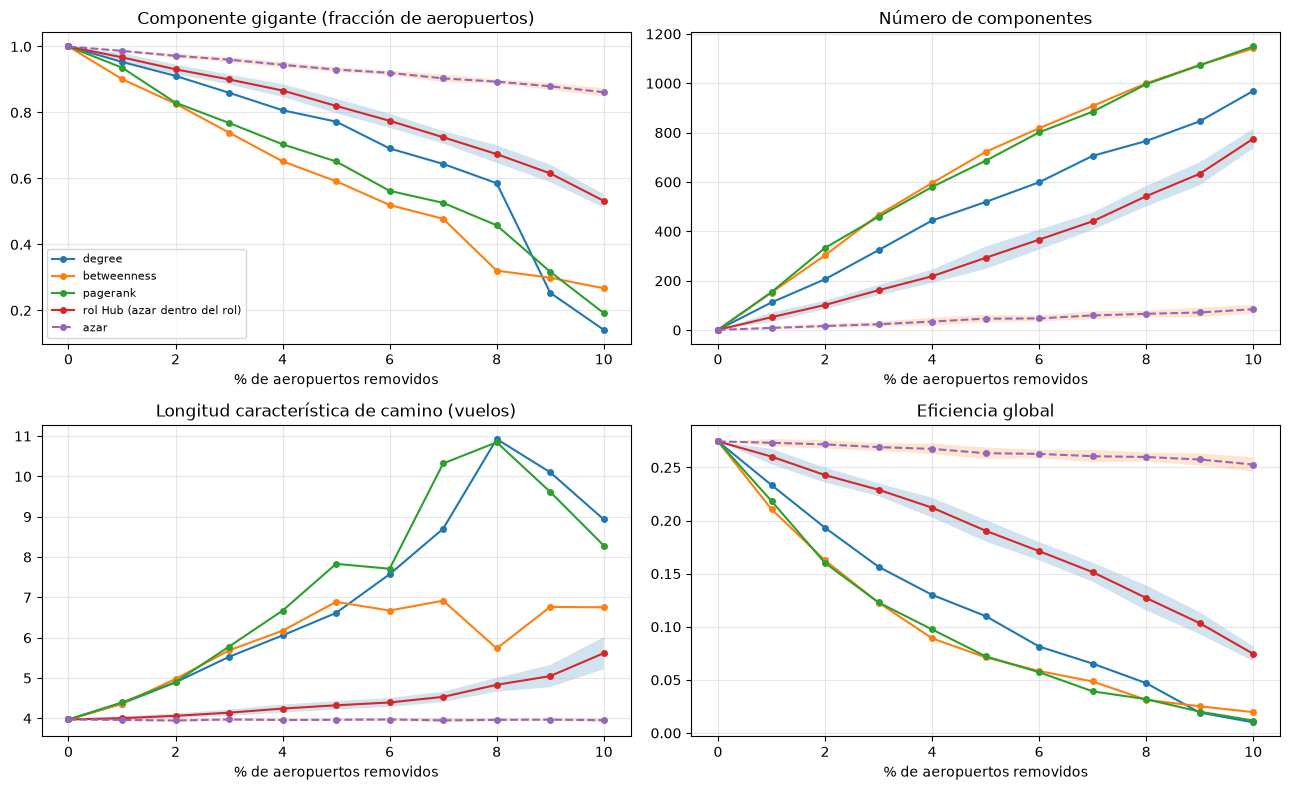

In [50]:
# 8.3 Curvas de fragmentación
orden_est = ["degree", "betweenness", "pagerank", "rol Hub (azar dentro del rol)", "azar"]
paneles = [("gigante", "Componente gigante (fracción de aeropuertos)"), ("componentes", "Número de componentes"),
           ("camino", "Longitud característica de camino (vuelos)"), ("eficiencia", "Eficiencia global")]
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
for eje, (col, titulo) in zip(ejes.ravel(), paneles):
    for est in orden_est:
        t = whatif[whatif["estrategia"] == est].groupby("pct")[col].agg(["mean", "std"]).fillna(0)
        eje.plot(t.index, t["mean"], marker="o", ms=4, label=est, linestyle="--" if est == "azar" else "-")
        if est in ("azar", "rol Hub (azar dentro del rol)"):
            eje.fill_between(t.index, t["mean"] - t["std"], t["mean"] + t["std"], alpha=0.2)
    eje.set_title(titulo); eje.set_xlabel("% de aeropuertos removidos"); eje.grid(alpha=0.3)
ejes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Interpretación: qué aeropuertos son críticos

- **La red resiste las fallas al azar y es frágil frente a los ataques dirigidos.** Si se sacan 319 aeropuertos al azar (10%), la componente gigante conserva el 86,1% de la red y la eficiencia global baja de 0,275 a 0,253. Si se sacan los 159 con más betweenness (5%), la gigante cae al 59,2% y la eficiencia a 0,071, es decir, **pierde el 74% de su eficiencia**.
- **El betweenness es el que más daña al principio:** con solo el 1% (32 aeropuertos), la gigante cae al 90,1%, frente al 95,3% con degree y 93,6% con PageRank. Hasta el 5% de remociones, los puentes (betweenness) y PageRank rompen más que los hubs por conexiones (degree). Esto confirma la hipótesis de la sección 3: un puente como Anchorage importa más de lo que su degree sugiere.
- **Pasada cierta fracción, degree colapsa la red:** con el 8% de remociones por degree la gigante aún tiene el 59%, y con el 10% queda en 14,1%. Es una transición abrupta: la red deja de ser una sola.
- **Las rutas se alargan:** de 3,97 vuelos entre dos aeropuertos a 6,9 (betweenness, 5%). La longitud de camino solo mira la componente gigante y deja de crecer cuando esta se desintegra, por eso las curvas bajan al final: no es que la red mejore, es que quedan menos aeropuertos conectados.
- **Pertenecer al rol Hub ya pesa:** sacar al azar aeropuertos del rol Hub (394 aeropuertos, 12% de la red) deja una gigante de 82,0% con el 5% de remociones y 53,2% con el 10%, frente a 93,0% y 86,1% al sacar aeropuertos cualquiera. Pero el orden dentro del rol importa mucho más: con betweenness, la gigante cae a 59,2% con el mismo 5%.
- **Fragmentación:** con el 10% de remociones por betweenness o PageRank, la red se parte en más de 1.100 componentes, frente a 85 al azar.
- **Límites:** el orden de remoción se calcula una sola vez sobre la red intacta (no se recalcula después de cada remoción); sacar un aeropuerto significa que sus rutas desaparecen del todo, sin reasignar capacidad; y la red no tiene pesos.

In [51]:
# 8.4 ¿Quién depende de un único aeropuerto? Los aeropuertos con una sola ruta quedan aislados si su vecino desaparece
dependientes = df_rol.index[df_rol["degree"] == 1]
unico_vecino = pd.Series({v: next(iter(Gc[v])) for v in dependientes})
print(f"Aeropuertos con una sola ruta: {len(dependientes)} de {N_gc} ({len(dependientes) / N_gc:.1%})")

por_vecino = unico_vecino.value_counts()
top_dep = pd.DataFrame({"aeropuerto": [df_nodos.loc[v, "etiqueta"] for v in por_vecino.index[:10]],
                        "ciudad": [df_nodos.loc[v, "ciudad"] for v in por_vecino.index[:10]],
                        "aeropuertos que dependen de él": por_vecino.values[:10]})
display(top_dep)
print(f"Los {len(por_vecino)} aeropuertos que sostienen a alguien: los 20 primeros concentran {por_vecino.head(20).sum() / len(dependientes):.1%} de los dependientes")

Aeropuertos con una sola ruta: 705 de 3188 (22.1%)


,aeropuerto,ciudad,aeropuertos que dependen de él
0,HND,Tokyo,14
1,BOG,Bogota,14
2,MNL,Manila,13
3,AEP,Buenos Aires,12
4,DMK,Bangkok,12
5,DEN,Denver,12
6,DFW,Dallas-Fort Worth,11
7,MEX,Mexico City,10
8,LIM,Lima,10
9,DME,Moscow,10


Los 290 aeropuertos que sostienen a alguien: los 20 primeros concentran 28.1% de los dependientes


In [52]:
# 8.5 ¿Reducen las rutas nuevas la dependencia? Damos una segunda ruta a cada uno de los aeropuertos de una sola ruta
# y repetimos el ataque con degree, betweenness y PageRank (órdenes de la red original).
E_gc = preparar(Gc, nodos_gc)
com_gc = np.array([com_nodo[v] for v in nodos_gc])
es_hub = np.zeros(N_gc, dtype=bool)
es_hub[hubs_gc] = True
dep_idx = np.array([pos_gc[v] for v in dependientes])

def destino(i, solo_otra_comunidad=False, sin_hubs=False):
    """Mejor destino nuevo para el aeropuerto i según PageRank personalizado, con restricciones opcionales."""
    s = puntajes(E_gc, i, "ppr").astype(float)
    if sin_hubs:
        s = np.where(es_hub, -np.inf, s)
    if solo_otra_comunidad:
        s = np.where(com_gc != com_gc[i], s, -np.inf)
    s[i] = -np.inf
    s[E_gc["M"].indices[E_gc["M"].indptr[i]:E_gc["M"].indptr[i + 1]]] = -np.inf
    return int(np.argmax(s))

rng = np.random.default_rng(SEED)
def azar_nuevos():
    pares = []
    while len(pares) < len(dep_idx):
        a, b = dep_idx[len(pares)], int(rng.integers(N_gc))
        if a != b and A_gc[a, b] == 0:
            pares.append((a, b))
    return pares

propuestas = {
    "sin rutas nuevas": [],
    "populares (todos al mayor hub)": [(i, int(np.argmax(E_gc["grado"]))) for i in dep_idx],
    "PageRank personalizado (la más probable)": [(i, destino(i)) for i in dep_idx],
    "PageRank personalizado, otra comunidad y sin hubs": [(i, destino(i, True, True)) for i in dep_idx],
    "azar": azar_nuevos(),
}

def con_rutas(pares):
    G2 = Gc.copy()
    G2.add_edges_from([(nodos_gc[a], nodos_gc[b]) for a, b in pares])
    return nx.to_scipy_sparse_array(G2, nodelist=nodos_gc, weight=None, format="csr")

filas = []
for nombre, pares in propuestas.items():
    A2 = con_rutas(pares)
    destinos = [b for _, b in pares]
    for ataque, orden in orden_det.items():
        for p in (5, 10):
            m = metricas_red(A2, np.setdiff1d(todos, orden[:round(p * N_gc / 100)]), rng)
            filas.append({"rutas nuevas": nombre, "ataque": ataque, "pct": p, "gigante": m["gigante"], "eficiencia": m["eficiencia"]})
whatif_rutas = pd.DataFrame(filas)

# Qué tipo de destino elige cada propuesta
descr = pd.DataFrame({nombre: {"rutas nuevas": len(p), "destinos distintos": len({b for _, b in p}),
                               "% a otra comunidad": round(100 * np.mean([com_gc[a] != com_gc[b] for a, b in p]), 1) if p else np.nan,
                               "degree medio del destino": round(np.mean([E_gc["grado"][b] for _, b in p]), 1) if p else np.nan}
                      for nombre, p in propuestas.items()}).T
display(descr)
display(whatif_rutas.pivot_table(index="rutas nuevas", columns=["ataque", "pct"], values="gigante", sort=False).round(3))

,rutas nuevas,destinos distintos,% a otra comunidad,degree medio del destino
sin rutas nuevas,0.0,0.0,NaN,NaN
populares (todos al mayor hub),705.0,1.0,88.7,248.0
PageRank personalizado (la más probable),705.0,146.0,6.0,107.0
"PageRank personalizado, otra comunidad y sin hubs",705.0,80.0,100.0,16.8
azar,705.0,634.0,84.3,12.8


ataque                                            degree        betweenness  \
pct                                                   5      10          5    
rutas nuevas                                                                  
sin rutas nuevas                                   0.772  0.141       0.592   
populares (todos al mayor hub)                     0.772  0.141       0.592   
PageRank personalizado (la más probable)           0.779  0.148       0.608   
PageRank personalizado, otra comunidad y sin hubs  0.866  0.685       0.773   
azar                                               0.865  0.691       0.822   

ataque                                                   pagerank         
pct                                                   10       5      10  
rutas nuevas                                                              
sin rutas nuevas                                   0.267    0.652  0.192  
populares (todos al mayor hub)                     0.267    0.652  0.192  
PageRank personalizado (la más probable)           0.267    0.670  0.192  
PageRank personalizado, otra comunidad y sin hubs  0.516    0.826  0.580  
azar                                               0.542    0.832  0.571

In [53]:
# 8.6 ¿Cuántas rutas hacen falta y en qué orden? Priorizamos a los aeropuertos que cuelgan de los hubs más intermediarios
bet_vecino = np.array([df_rol.loc[unico_vecino[v], "betweenness"] for v in dependientes])
prioridad = np.argsort(-bet_vecino)
pares_res = propuestas["PageRank personalizado, otra comunidad y sin hubs"]

filas = []
for K in [0, 100, 250, 500, len(dep_idx)]:
    A2 = con_rutas([pares_res[j] for j in prioridad[:K]])
    fila = {"rutas nuevas (K)": K, "% de las rutas actuales": round(100 * K / Gc.number_of_edges(), 1)}
    for ataque in ["degree", "betweenness"]:
        for p in (5, 10):
            fila[f"{ataque} {p}%"] = metricas_red(A2, np.setdiff1d(todos, orden_det[ataque][:round(p * N_gc / 100)]), rng)["gigante"]
    filas.append(fila)
curva_K = pd.DataFrame(filas).set_index("rutas nuevas (K)").round(3)
display(curva_K)

,% de las rutas actuales,degree 5%,degree 10%,betweenness 5%,betweenness 10%
rutas nuevas (K),,,,,
0,0.0,0.772,0.141,0.592,0.267
100,0.5,0.802,0.152,0.616,0.275
250,1.3,0.836,0.167,0.653,0.290
500,2.7,0.857,0.180,0.720,0.331
705,3.7,0.866,0.685,0.773,0.516


### Interpretación: qué rutas nuevas reducen la dependencia

- **Mucha de la fragilidad viene de los aeropuertos de una sola ruta:** son 705 de 3.188 (22,1%) y cuelgan de 290 aeropuertos distintos. Los más cargados son Tokio Haneda y Bogotá (14 cada uno), Manila (13) y Buenos Aires Aeroparque (12), pero la dependencia está repartida: los 20 primeros concentran solo el 28,1%.
- **Las rutas más probables no ayudan:** si a cada aeropuerto de una sola ruta le damos la que recomienda PageRank personalizado, el destino promedio tiene 107 rutas y solo el 6% está en otra comunidad. Son los mismos hubs que un ataque remueve primero, así que la mejora es casi nula (con el 10% de remociones por degree, la gigante pasa de 0,141 a 0,148). Conectar a todos con el mayor hub no cambia nada: el ataque lo saca primero. **El recomendador más preciso refuerza la dependencia en lugar de reducirla.**
- **Las rutas que sí ayudan unen aeropuertos pequeños de otras comunidades:** si elegimos, con el mismo PageRank personalizado, el mejor destino que esté en otra comunidad y no sea del rol Hub (destino promedio de 16,8 rutas), la gigante pasa de 0,772 a 0,866 con el 5% de remociones por degree, y de 0,141 a 0,689 con el 10%. Con betweenness pasa de 0,592 a 0,773 (5%) y de 0,267 a 0,516 (10%); con PageRank, de 0,652 a 0,826 y de 0,192 a 0,580.
- **No es mejor que el azar, y hay que decirlo:** conectar al azar da resultados parecidos (con el 5% por degree, 0,865). Lo que importa es que sean enlaces de largo alcance entre aeropuertos pequeños de comunidades distintas. La ventaja del recomendador es que propone rutas con cercanía estructural (destinos a pocos saltos), no que resista mejor.
- **Cuántas y en qué orden:** con 100 rutas (0,5% de las actuales), priorizando a los que cuelgan de los aeropuertos con más betweenness, la gigante sube 3 puntos (con el 5% por degree, de 0,772 a 0,802). Con 250 sube a 0,836, con 500 a 0,857 y con las 705 a 0,866. Con ataques por betweenness, las ganancias crecen: 0,616, 0,653, 0,720 y 0,773. No probamos otros órdenes de prioridad.
- **Cuidado con el 10% por degree:** ahí la ganancia salta de 0,180 (500 rutas) a 0,689 (705 rutas). La red está cerca del punto donde deja de ser una sola, y cualquier cambio pequeño la cruza. Usamos los resultados con el 5% como los más estables.
- **Límites:** los ataques usan el orden de la red original (las rutas nuevas también cambiarían los rankings); no evaluamos costo, distancia ni demanda de las rutas propuestas; y el recomendador "otra comunidad y sin hubs" renuncia a propósito a las rutas más probables, por lo que no medimos su HitRate.

# 9. Hallazgos y recomendación accionable

**Pregunta del proyecto:** ¿qué aeropuertos son críticos para mantener conectada la red mundial de rutas aéreas y qué rutas nuevas convendría sugerir para reducir esa dependencia?

## 9.1 Qué aeropuertos son críticos

- **La criticidad depende de qué se mida.** Los mayores hubs por conexiones (Ámsterdam 248, Frankfurt 244, París 240, Estambul 233, Atlanta 217) no coinciden del todo con los mayores puentes. Por betweenness lideran París, Los Ángeles, Anchorage, Dubái y Frankfurt: Anchorage es un puente que su número de rutas no deja ver.
- **La red es robusta frente a fallas al azar y frágil frente a ataques dirigidos.** Sacar el 10% de los aeropuertos al azar deja una componente gigante de 86,1%. Sacar solo el 5% con más betweenness la deja en 59,2% y la eficiencia global cae de 0,275 a 0,071. Sacar el 10% con más degree la deja en 14,1%.
- **Los más dañinos primero son los puentes.** Hasta el 5% de remociones, betweenness y PageRank rompen más la red que degree. Pasado ese punto, degree produce el colapso más abrupto.
- **Pertenecer al rol Hub no basta para ser crítico.** Sacar al azar aeropuertos del rol Hub deja la gigante en 82,0% (5%) y 53,2% (10%). El orden dentro del rol pesa más: con betweenness, el mismo 5% la deja en 59,2%.

## 9.2 De quién depende la red

- **705 de 3.188 aeropuertos (22,1%) tienen una sola ruta.** Si desaparece su único vecino, quedan aislados. Esos 705 cuelgan de 290 aeropuertos distintos, y los 20 más cargados concentran solo el 28,1% de ellos (Tokio Haneda y Bogotá con 14 dependientes cada uno, Manila 13, Buenos Aires Aeroparque 12). La dependencia está repartida, no concentrada en unos pocos puntos.

## 9.3 Qué rutas nuevas conviene sugerir

- **No conviene sugerir las rutas más probables.** El recomendador más preciso (PageRank personalizado, HitRate@10 de 0,359 frente a 0,082 de los populares) propone destinos con 107 rutas en promedio, y solo el 6% está en otra comunidad. Son los hubs que un ataque saca primero: con 10% de remociones por degree, la gigante pasa de 0,141 a 0,148. **Acertar más y reducir la dependencia son objetivos distintos.**
- **Sí conviene sugerir rutas de largo alcance entre aeropuertos pequeños de comunidades distintas.** Para los 705 aeropuertos de una sola ruta, el mejor destino de otra comunidad y fuera del rol Hub (destino con 16,8 rutas en promedio) sube la gigante de 0,772 a 0,866 con 5% de remociones por degree, y de 0,592 a 0,773 con 5% por betweenness.
- **Priorización:** empezar por los aeropuertos que cuelgan de los de mayor betweenness. Con 100 rutas (0,5% de las actuales) la gigante sube de 0,772 a 0,802; con 250, a 0,836; con 500, a 0,857; con las 705, a 0,866 (5% por degree).
- **Dentro del recomendador,** la variante `puentes` (λ = 0,5) es la que se alinea con este objetivo: el acierto en rutas entre comunidades sube de 0,239 a 0,337 y la novedad de 0,153 a 0,291, a costa de 1,9 puntos de HitRate@10 (0,359 a 0,340).

## 9.4 Qué no podemos afirmar

- **Las rutas que ayudan no son mejores que el azar:** conectar al azar da resultados parecidos (0,865 con 5% por degree). Lo que importa es que sean enlaces de largo alcance entre aeropuertos pequeños; la ventaja del recomendador es proponerlos con cercanía estructural (destinos a pocos saltos), no que resistan más.
- **El resultado con 10% por degree es inestable:** la ganancia salta de 0,180 (500 rutas) a 0,689 (705 rutas) porque la red está cerca del punto donde deja de ser una sola. Apoyamos las conclusiones en el 5%.
- **Límites de datos y método:** OpenFlights es de 2014; un acierto es recuperar una ruta que existía entonces; la red no tiene pesos (frecuencias, capacidad); el orden de los ataques se calcula una sola vez sobre la red intacta; no evaluamos costo, distancia ni demanda de las rutas propuestas; y no medimos el HitRate del recomendador "otra comunidad y sin hubs".

## 9.5 Recomendación

> Proteger (con redundancia o planes de contingencia) los aeropuertos de mayor betweenness, y para reducir la dependencia sugerir, **en vez de la ruta más probable**, rutas entre aeropuertos pequeños de comunidades distintas, empezando por los que hoy cuelgan de un único aeropuerto de alto betweenness. El recomendador de la app permite elegir esa variante (`puentes`) y ver el costo en precisión.

# 10. Exportación de CSV para el dashboard

La app (`app.py`) no recalcula nada pesado: lee estos archivos, que se guardan en la carpeta `data/`.

| Archivo | Contenido |
|---|---|
| `nodos.csv` | Un aeropuerto por fila: centralidades, comunidad, rol estructural, coordenadas y posición en el mapa del ACP. |
| `aristas.csv` | Una fila por ruta. Permite armar el grafo, la red del ego y los aeropuertos hipotéticos del recomendador. |
| `recomendaciones.csv` | Las 10 mejores recomendaciones de cada aeropuerto para seis variantes del recomendador. |
| `hitrate.csv` | Resultado de la evaluación offline (promedio y desviación de las 5 particiones). |
| `whatif.csv` | Curvas de la simulación de fragmentación (promedio y desviación por estrategia y porcentaje removido). |
| `whatif_rutas.csv` y `curva_K.csv` | Efecto de las rutas nuevas sobre la resistencia de la red (sección 8.5 y 8.6). |
| `comparacion.csv`, `comunidades.csv`, `roles.csv`, `centroides_roles.csv` | Tablas de resumen que muestra el dashboard. |

In [54]:
# 10.1 nodos.csv y aristas.csv
import os
os.makedirs("data", exist_ok=True)

nodos_csv = df_nodos[["etiqueta", "iata", "nombre", "ciudad", "pais", "degree", "closeness", "betweenness",
                      "eigenvector", "pagerank", "clustering"]].copy()
nodos_csv["lat"] = [G.nodes[n]["lat"] for n in nodos_csv.index]
nodos_csv["lon"] = [G.nodes[n]["lon"] for n in nodos_csv.index]
nodos_csv["comunidad"] = df_nodos["com_louvain"]
nodos_csv["comunidad_greedy"] = df_nodos["com_greedy"]
nodos_csv["rol"] = df_rol["rol"]                              # vacío fuera de la componente gigante
nodos_csv["PC1"] = df_rol["PC1"]                              # posición en el mapa del ACP (sección 5.6)
nodos_csv["PC2"] = df_rol["PC2"]
nodos_csv.to_csv("data/nodos.csv", index_label="id")

pd.DataFrame(list(G.edges()), columns=["origen", "destino"]).to_csv("data/aristas.csv", index=False)
print(f"nodos.csv: {len(nodos_csv)} aeropuertos | aristas.csv: {G.number_of_edges()} rutas")

nodos.csv: 3214 aeropuertos | aristas.csv: 18858 rutas


In [55]:
# 10.2 recomendaciones.csv: las 10 mejores recomendaciones de cada aeropuerto, para seis variantes (tarda cerca de 1 minuto)
VARIANTES_REC = [("ppr", "ppr", "ninguno", 0.0), ("ppr + puentes (λ=0.5)", "ppr", "puentes", 0.5),
                 ("ppr + dentro (λ=1)", "ppr", "dentro", 1.0), ("adamic_adar", "adamic_adar", "ninguno", 0.0),
                 ("jaccard", "jaccard", "ninguno", 0.0), ("vecinos_comunes", "vecinos_comunes", "ninguno", 0.0)]
TOP = 10
M_, grado_, indptr_, indices_ = E_G["M"], E_G["grado"], E_G["M"].indptr, E_G["M"].indices
com_arr = np.array([com_nodo[v] for v in nodos])
populares = np.argsort(-grado_, kind="stable")
n_nodos = len(nodos)

filas = []
for i, origen in enumerate(nodos):
    vecinos_i = indices_[indptr_[i]:indptr_[i + 1]]
    excluidos = np.zeros(n_nodos, dtype=bool)
    excluidos[i] = True
    excluidos[vecinos_i] = True
    bases = {m: puntajes(E_G, i, m).astype(float) for m in ["vecinos_comunes", "jaccard", "adamic_adar", "ppr"]}
    comunes = bases["vecinos_comunes"]
    for nombre, metodo, modo, lam in VARIANTES_REC:
        base = bases[metodo]
        s = base.copy()
        if modo != "ninguno" and lam > 0:
            s = s * (1 + lam * ((com_arr == com_arr[i]) if modo == "dentro" else (com_arr != com_arr[i])))
        s[excluidos] = -np.inf
        elegidos = [j for j in np.argsort(-s, kind="stable")[:TOP] if s[j] > 0]
        respaldo = []
        if len(elegidos) < TOP:                                       # se completa con los más populares
            for j in populares:
                if not excluidos[j] and j not in elegidos:
                    respaldo.append(j)
                if len(elegidos) + len(respaldo) == TOP:
                    break
        for r, (j, es_resp) in enumerate([(j, False) for j in elegidos] + [(j, True) for j in respaldo], start=1):
            filas.append((origen, nodos[j], nombre, r, grado_[j] if es_resp else base[j], int(com_arr[j]),
                          bool(com_arr[j] != com_arr[i]), int(comunes[j]), es_resp))
recomendaciones = pd.DataFrame(filas, columns=["id_origen", "id_destino", "variante", "rank", "puntaje",
                                               "comunidad_destino", "otra_comunidad", "vecinos_comunes", "respaldo"])
recomendaciones.to_csv("data/recomendaciones.csv", index=False)
print(f"recomendaciones.csv: {len(recomendaciones):,} filas ({os.path.getsize('data/recomendaciones.csv') / 1e6:.1f} MB)")

# Control: la versión masiva debe dar lo mismo que la función recomendar() de la sección 6
rng_ctrl = np.random.default_rng(SEED)
ok = 0
for i in rng_ctrl.choice(n_nodos, 25, replace=False):
    for nombre, metodo, modo, lam in VARIANTES_REC:
        ref = recomendar(nodos[i], G, TOP, metodo, modo=modo, lam=lam, E=E_G)["etiqueta"].tolist()
        sub = recomendaciones[(recomendaciones["id_origen"] == nodos[i]) & (recomendaciones["variante"] == nombre)].sort_values("rank")
        ok += ref == [df_nodos.loc[d, "etiqueta"] for d in sub["id_destino"]]
print(f"Control contra recomendar(): {ok} de {25 * len(VARIANTES_REC)} listas idénticas")

recomendaciones.csv: 192,840 filas (11.1 MB)
Control contra recomendar(): 150 de 150 listas idénticas


In [56]:
# 10.3 hitrate.csv, whatif.csv y tablas de resumen
hitrate = media.join(desv, rsuffix="_desv").reset_index()
hitrate.to_csv("data/hitrate.csv", index=False)

agg = whatif.groupby(["estrategia", "pct"])[["gigante", "componentes", "camino", "eficiencia"]].agg(["mean", "std"])
agg.columns = [f"{a}_{b}" for a, b in agg.columns]
agg.fillna(0).reset_index().to_csv("data/whatif.csv", index=False)
whatif_rutas.to_csv("data/whatif_rutas.csv", index=False)
curva_K.reset_index().to_csv("data/curva_K.csv", index=False)

comparacion.to_csv("data/comparacion.csv", index_label="medida")
comunidades_res = pd.DataFrame({
    "Greedy modularity": [len(com_greedy), nx.community.modularity(G, com_greedy, weight=None), len(com_greedy[0])],
    "Louvain": [len(com_louvain), nx.community.modularity(G, com_louvain, weight=None), len(com_louvain[0])],
}, index=["comunidades", "modularidad", "comunidad mayor"])
comunidades_res.to_csv("data/comunidades.csv", index_label="medida")
perfil.to_csv("data/roles.csv", index_label="rol")
pd.DataFrame({"rol": roles_orden, "PC1": cent_pca[:, 0], "PC2": cent_pca[:, 1]}).to_csv("data/centroides_roles.csv", index=False)
pd.Series({"PC1": varianza.iloc[0], "PC2": varianza.iloc[1]}, name="varianza").to_csv("data/varianza_pca.csv", index_label="componente")

for f in sorted(os.listdir("data")):
    print(f"{f:28s} {os.path.getsize('data/' + f) / 1e3:9.1f} KB")

aristas.csv                      181.0 KB
centroides_roles.csv               0.3 KB
comparacion.csv                    0.3 KB
comunidades.csv                    0.1 KB
curva_K.csv                        0.2 KB
hitrate.csv                        4.5 KB
nodos.csv                        755.4 KB
recomendaciones.csv            11117.1 KB
roles.csv                          0.8 KB
varianza_pca.csv                   0.1 KB
whatif.csv                         6.5 KB
whatif_rutas.csv                   2.5 KB
